<a href="https://colab.research.google.com/github/marcoskantor/Curso_Introduccion_Ingenieria_Datos/blob/main/TP4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP4 — Detección de eventos atípicos en GDELT 2.0

**Curso:** Introducción a la Ingeniería de Datos — Doctorado
**Autor:** Marcos Kantor

**Objetivo:** encontrar en la tabla de eventos de GDELT 2.0 de los últimos 7 días los **eventos "raros"** que valga la pena investigar.

**Pipeline del notebook**

| Etapa | Qué se hace | Producto |
|---|---|---|
| 1. Ingesta | Descarga de las tablas *Event* (`export.CSV.zip`) de 15 minutos de los últimos 7 días desde `masterfilelist.txt`, verificación MD5 y desnormalización con los libros de códigos CAMEO/FIPS | `gdelt_obt_7d.parquet` (One Big Table) |
| 2.1 Nulos y ceros | Faltantes estructurales vs. reales, auditoría de consistencia lógica, criterio de descarte/imputación por variable | matriz analítica limpia |
| 2.2 Cardinalidad | Categorías con frecuencia < 5 % → `OTHER` | categóricas reducidas |
| 2.3 Variables indicadoras | *One-hot encoding* (dummies) con categoría de referencia | matriz numérica |
| 2.4 ACP | Escalado + Análisis por Componentes Principales, selección del número mínimo de componentes | matriz de *scores* |
| 2.5 Atípicos | 10 métodos de 6 familias (distancia global, ACP T²/SPE, K-Means, k-NN, LOF/DBSCAN, Isolation Forest, autoencoder), comparación por Jaccard y consenso por mayoría | `gdelt_atipicos.parquet` / `.csv` |

## Declaración de uso de Inteligencia Artificial

| Herramienta | Propósito |
|---|---|
| **Claude Opus 5.5** (Anthropic, vía Claude Code) | Generación del código fuente Python del notebook (ingesta, limpieza, ACP y detección de atípicos) y borrador de las celdas Markdown explicativas. |

Todas las decisiones metodológicas (umbral del 5 % de cardinalidad, criterio de imputación, regla de selección de componentes, nivel de significancia de los límites de control y regla de consenso) fueron definidas, revisadas y validadas por el autor. Los resultados numéricos se obtienen ejecutando el notebook; no fueron generados por la IA.

### Guía de instrucciones para reproducir el resultado (*Human-in-the-loop*)

La siguiente secuencia de instrucciones permite reproducir el notebook con la herramienta de IA. Cada paso indica la instrucción dada y la **verificación humana** realizada antes de pasar al siguiente.

1. **Contexto y arquitectura.**
   *"Actuá como ingeniero de datos. Necesito un notebook de Google Colab en Python que construya un pipeline batch sobre la tabla de hechos Event de GDELT 2.0 (61 campos, codebook V2.0). El pipeline tiene etapas: ingesta → One Big Table desnormalizada → limpieza → reducción de cardinalidad → variables indicadoras → ACP → detección de atípicos multivariantes. Usá pandas, pyarrow, scikit-learn y scipy; todo parametrizado en una celda de configuración."*
   ✔ Verifiqué que los 61 nombres de columna coincidan con el codebook GDELT-Event_Codebook-V2.0 y que los códigos CAMEO (`EventCode`, `EventRootCode`) se lean como texto para no perder ceros a la izquierda.

2. **Ingesta incremental e idempotente.**
   *"Leé `masterfilelist.txt` en streaming, filtrá solo los archivos `.export.CSV.zip` cuya marca temporal (YYYYMMDDHHMMSS) esté dentro de una ventana deslizante de 7 días en UTC, descargalos en paralelo con reintentos, validá el MD5 y el tamaño informados en la lista maestra, cacheá en disco y registrá los intervalos de 15 minutos faltantes."*
   ✔ Controlé la completitud: 7 × 96 = 672 intervalos esperados vs. descargados.

3. **Desnormalización (One Big Table).**
   *"Construí una OBT: a la tabla de hechos agregale las descripciones de las dimensiones (lookups CAMEO de eventos, países, tipos de actor, grupos, religiones, etnias; FIPS para geografía; QuadClass y Geo_Type), atributos derivados de tiempo (fecha de publicación, hora, día de semana, días de retraso entre SQLDATE y DATEADDED) y el dominio de la fuente. Eliminá duplicados por GLOBALEVENTID y persistí en Parquet con compresión snappy."*
   ✔ Revisé que el *grain* sea un evento por fila y que no se multipliquen filas al desnormalizar (uso de `map` en lugar de `merge`).

4. **Calidad de datos: nulos, ceros y consistencia.**
   *"Antes de imputar, distinguí ausencia estructural de faltante real: si no hay Actor2 (Actor2Code nulo) sus atributos son nulos por diseño y se codifican como 'SIN_ACTOR2'; si el actor existe pero falta su país, es un faltante real ('UNKNOWN'). Auditá reglas de consistencia lógica del codebook (QuadClass derivada de EventRootCode, EventRootCode prefijo de EventCode, NumSources ≤ NumArticles ≤ NumMentions, rangos de GoldsteinScale, AvgTone y coordenadas, DATEADDED posterior a SQLDATE, Goldstein único por EventCode) y corregí sólo lo determinístico; lo imposible se descarta y lo dudoso se reporta. Después del one-hot, controlá varianza casi nula con razón de frecuencias y % de valores distintos (no con coeficiente de variación); reportalas pero no las elimines, porque en detección de atípicos una variable casi constante puede ser la que delata al evento raro: eliminá sólo las constantes."*
   *"Generá un perfil de faltantes con % de nulos y % de ceros por columna. Distinguí ceros estructurales (GoldsteinScale y AvgTone = 0 son valores válidos, neutros) de ceros que representan faltantes (lat = long = 0, 'Null Island'). Para categóricas, tratá el nulo como categoría 'UNKNOWN' porque es faltante no aleatorio (MNAR); imputá coordenadas por mediana del país del ActionGeo; imputá GoldsteinScale por la moda del EventCode, ya que es función determinística del código CAMEO; descartá el resto y reportá cuántas filas se pierden."*
   ✔ Validé que el descarte de filas sea marginal (< 5 %) antes de aceptar el criterio.

5. **Transformaciones.**
   *"Los eventos con DiasRetraso exactamente 7, 30, 365 o 3650 días son fechas relativas inferidas por GDELT ('hace un año'): separalos como hallazgo de calidad (es_retrospectiva) y no los uses como variable del detector, porque una variable que vale 0 en el 98 % de los casos domina cualquier distancia. Reemplazá los conteos crudos por su percentil (cobertura en artículos, fuentes y amplificación = menciones por artículo), que es acotado y no deja que unos pocos valores extremos dominen. La ubicación entra sólo como país (dummies): verificá que las coordenadas continuas no conviertan a toda minoría geográfica en atípico."*

6. **Reducción de cardinalidad y variables indicadoras.**
   *"Para cada categórica agrupá en 'OTHER' las categorías con frecuencia relativa menor al 5 % de la muestra; mostrá cardinalidad antes/después. Luego hacé one-hot encoding eliminando una categoría de referencia ('OTHER' si existe, si no la más frecuente) para evitar la colinealidad perfecta (trampa de las dummies)."*

7. **ACP.**
   *"Escalá con RobustScaler (mediana y rango intercuartílico) en lugar de z-score: es resistente a las colas y no infla las dummies de categorías poco frecuentes. Ajustá PCA con todos los componentes, graficá scree plot y varianza acumulada, y compará criterios: varianza acumulada ≥ 80 % y ≥ 90 %, Kaiser generalizado (autovalor mayor que el promedio, porque con escalado robusto las variables no tienen varianza 1) y codo. Elegí el número mínimo de componentes con el criterio de 80 % de varianza explicada y mostrá las cargas (loadings)."*
   ✔ Revisé que la cantidad elegida sea coherente entre criterios e interpreté las primeras componentes.

8. **Atípicos multivariantes (siguiendo el notebook de referencia de la cátedra *Cardiotocography outliers*).**
   *"Tomá como guía las familias de métodos del notebook de Cardiotocography y aplicalas sobre los scores del ACP: distancia euclídea al centroide con Z-score > 3 (verificando el supuesto de normalidad con curtosis y Anderson-Darling) y Tukey fences 2·IQR; T² de Hotelling con límite χ²(0,999; K) y SPE con la aproximación de Box; K-Means (distancia al centroide del grupo), k-NN (distancia media a los vecinos), LOF y DBSCAN (eps por gráfico de k-distancias); Isolation Forest y un autoencoder denso en PyTorch con error de reconstrucción. Como GDELT no tiene etiquetas, reemplazá la matriz de confusión por el índice de Jaccard entre métodos y un consenso por mayoría de votos. Para escalar a ~10⁶ eventos, ajustá los métodos O(n²) sobre una muestra de referencia y evaluá todos los eventos en modo novelty. Explicá cada atípico con las variables de mayor valor escalado y de mayor residuo, asignale un tipo según la variable dominante, agrupalos por noticia (SOURCEURL) para no repetir la misma historia y exportá ambas tablas a Parquet y CSV."*
   ✔ Inspeccioné manualmente los 25 atípicos más extremos abriendo su `SOURCEURL`.

## 0. Configuración del entorno

In [37]:
# En Colab todas estas librerías ya están instaladas; se fuerza pyarrow por las dudas.
!pip -q install pyarrow

In [38]:
import csv, hashlib, io, re, time, zipfile, warnings
from concurrent.futures import ThreadPoolExecutor, as_completed
from datetime import datetime, timedelta, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from scipy.stats import chi2, zscore, anderson
from sklearn.preprocessing import RobustScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.cluster import MiniBatchKMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors, LocalOutlierFactor
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# ----------------------------- parámetros del pipeline -----------------------------
DIAS          = 7          # ventana deslizante de ingesta
MAX_ARCHIVOS  = None       # p.ej. 96 para una prueba rápida (1 día); None = ventana completa
MAX_WORKERS   = 16         # descargas en paralelo
UMBRAL_RARO   = 0.05       # categorías con frecuencia < 5 % -> 'OTHER'
UMBRAL_VAR    = 0.80       # varianza acumulada mínima para elegir K componentes
ALPHA         = 0.999      # nivel de confianza de los límites de control (T², SPE)
TOP_FRAC      = 0.01       # fracción superior marcada por los métodos de score continuo
N_REF         = 20_000     # muestra de referencia para k-NN / LOF / DBSCAN (métodos O(n²))
K_CLUSTERS    = 10         # grupos de K-Means
K_VECINOS     = 10         # vecinos para k-NN y LOF
DIM_LATENTE   = 4          # dimensión del espacio latente del autoencoder
EPOCAS_AE     = 15         # épocas de entrenamiento del autoencoder
SEED          = 42

DATA_DIR = Path("/content/gdelt_tp4") if Path("/content").exists() else Path("gdelt_tp4")
RAW_DIR  = DATA_DIR / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
OBT_PATH = DATA_DIR / "gdelt_obt_7d.parquet"
ATI_PATH = DATA_DIR / "gdelt_atipicos.parquet"
print("Directorio de trabajo:", DATA_DIR.resolve())

Directorio de trabajo: /content/gdelt_tp4


## 1. Ingesta de datos

### 1.1 Esquema de la tabla *Event* (GDELT 2.0)

Cada archivo `YYYYMMDDHHMMSS.export.CSV.zip` contiene un TSV sin encabezado con **61 campos** (codebook V2.0). Los códigos CAMEO y de país se leen como **texto** para conservar ceros a la izquierda (`"010"` ≠ `10`).

In [39]:
ACTOR = ["Code", "Name", "CountryCode", "KnownGroupCode", "EthnicCode",
         "Religion1Code", "Religion2Code", "Type1Code", "Type2Code", "Type3Code"]
GEO   = ["Type", "FullName", "CountryCode", "ADM1Code", "ADM2Code", "Lat", "Long", "FeatureID"]

COLS = (["GLOBALEVENTID", "SQLDATE", "MonthYear", "Year", "FractionDate"]
        + [f"Actor1{c}" for c in ACTOR] + [f"Actor2{c}" for c in ACTOR]
        + ["IsRootEvent", "EventCode", "EventBaseCode", "EventRootCode", "QuadClass",
           "GoldsteinScale", "NumMentions", "NumSources", "NumArticles", "AvgTone"]
        + [f"Actor1Geo_{c}" for c in GEO] + [f"Actor2Geo_{c}" for c in GEO]
        + [f"ActionGeo_{c}" for c in GEO]
        + ["DATEADDED", "SOURCEURL"])
assert len(COLS) == 61

COLS_NUM = (["IsRootEvent", "QuadClass", "GoldsteinScale", "NumMentions", "NumSources",
             "NumArticles", "AvgTone", "Year", "FractionDate"]
            + [f"{p}Geo_{c}" for p in ("Actor1", "Actor2", "Action") for c in ("Type", "Lat", "Long")])

### 1.2 Selección de archivos desde `masterfilelist.txt`

La lista maestra tiene una línea por archivo: `tamaño md5 url`. Se lee en *streaming* (es grande) y se filtran sólo las tablas de evento (`export.CSV.zip`) dentro de la ventana de 7 días en UTC.

In [40]:
MASTER_URL = "http://data.gdeltproject.org/gdeltv2/masterfilelist.txt"

def listar_exports(dias: int) -> pd.DataFrame:
    corte = (datetime.now(timezone.utc) - timedelta(days=dias)).strftime("%Y%m%d%H%M%S")
    filas = []
    with requests.get(MASTER_URL, stream=True, timeout=300) as r:
        r.raise_for_status()
        for linea in r.iter_lines(decode_unicode=True):
            if not linea or not linea.endswith(".export.CSV.zip"):
                continue
            partes = linea.split()
            if len(partes) != 3:
                continue
            size, md5, url = partes
            ts = url.rsplit("/", 1)[-1].split(".")[0]
            if ts >= corte:
                filas.append((ts, int(size), md5, url))
    return (pd.DataFrame(filas, columns=["timestamp", "size", "md5", "url"])
              .drop_duplicates("timestamp").sort_values("timestamp").reset_index(drop=True))

archivos = listar_exports(DIAS)
if MAX_ARCHIVOS:
    archivos = archivos.tail(MAX_ARCHIVOS).reset_index(drop=True)

esperados = DIAS * 96 if not MAX_ARCHIVOS else MAX_ARCHIVOS
print(f"Archivos en ventana: {len(archivos)} (esperados ≈ {esperados})")
print("Desde", archivos.timestamp.min(), "hasta", archivos.timestamp.max())
archivos.head()

Archivos en ventana: 673 (esperados ≈ 672)
Desde 20261008231500 hasta 20261015231500


,timestamp,size,md5,url
0,20261008231500,63549,c405e318bcc6d08306cb8af12365c67d,http://data.gdeltproject.org/gdeltv2/202610082...
1,20261008233000,76221,f14785eafc9cd707412e15777f58489b,http://data.gdeltproject.org/gdeltv2/202610082...
2,20261008234500,66054,c3bd306c7881ab6f2901bd430dd4d39f,http://data.gdeltproject.org/gdeltv2/202610082...
3,20261009000000,148099,92ea70ffc5ddee99564f277bdf521214,http://data.gdeltproject.org/gdeltv2/202610090...
4,20261009001500,114812,85c06cd33305b20f3b4222a8ca31d1c8,http://data.gdeltproject.org/gdeltv2/202610090...


### 1.3 Descarga paralela con verificación de integridad

Cada archivo se descarga con reintentos, se valida contra el **MD5** de la lista maestra y se cachea en disco (re-ejecutar el notebook no vuelve a descargar). El parseo convierte tipos por archivo para controlar el uso de memoria.

In [41]:
def descargar(row) -> Path:
    destino = RAW_DIR / row.url.rsplit("/", 1)[-1]
    if destino.exists() and destino.stat().st_size == row.size:
        return destino
    err = None
    for intento in range(4):
        try:
            r = requests.get(row.url, timeout=90)
            r.raise_for_status()
            if hashlib.md5(r.content).hexdigest() != row.md5:
                raise ValueError("MD5 no coincide")
            destino.write_bytes(r.content)
            return destino
        except Exception as e:
            err = e
            time.sleep(2 * (intento + 1))
    raise RuntimeError(f"{row.url}: {err}")

def leer_export(path: Path, ts: str) -> pd.DataFrame:
    with zipfile.ZipFile(path) as z, z.open(z.namelist()[0]) as f:
        df = pd.read_csv(f, sep="\t", header=None, names=COLS, dtype=str,
                         quoting=csv.QUOTE_NONE, on_bad_lines="skip",
                         keep_default_na=False, na_values=[""],
                         encoding="utf-8", encoding_errors="replace")
    for c in COLS_NUM:
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df["GLOBALEVENTID"] = pd.to_numeric(df["GLOBALEVENTID"], errors="coerce")
    df["ArchivoOrigen"] = ts
    return df

def procesar(row):
    return leer_export(descargar(row), row.timestamp)

partes, fallidos = [], []
with ThreadPoolExecutor(MAX_WORKERS) as ex:
    futuros = {ex.submit(procesar, row): row.timestamp for row in archivos.itertuples()}
    for fut in tqdm(as_completed(futuros), total=len(futuros), desc="Event 15'"):
        try:
            partes.append(fut.result())
        except Exception as e:
            fallidos.append((futuros[fut], str(e)))

eventos = pd.concat(partes, ignore_index=True)
del partes
print(f"Intervalos OK: {len(archivos) - len(fallidos)} | fallidos: {len(fallidos)}")
print(f"Filas leídas: {len(eventos):,}")

Event 15':   0%|          | 0/673 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Intervalos OK: 673 | fallidos: 0
Filas leídas: 727,359


### 1.4 Construcción de la One Big Table (OBT)

La OBT **desnormaliza** el modelo estrella de GDELT: a la tabla de hechos se le agregan los atributos descriptivos de las dimensiones (libros de códigos CAMEO / FIPS publicados por GDELT) y atributos derivados de tiempo y fuente. Se usa `Series.map` con diccionarios para garantizar que el *grain* (un evento por fila) no cambie.

In [42]:
LOOKUP_URL = "https://www.gdeltproject.org/data/lookups/{}"

def cargar_lookup(nombre: str) -> dict:
    try:
        lk = pd.read_csv(LOOKUP_URL.format(nombre), sep="\t", header=None, usecols=[0, 1],
                         names=["code", "label"], dtype=str, quoting=csv.QUOTE_NONE,
                         encoding_errors="replace")
        lk = lk.dropna()
        lk = lk[~lk["code"].str.upper().str.contains("CODE")]          # descarta encabezado
        return dict(zip(lk["code"].str.strip(), lk["label"].str.strip()))
    except Exception as e:
        print(f"[aviso] no se pudo cargar {nombre}: {e}")
        return {}

LK = {n: cargar_lookup(f"{n}.txt") for n in
      ["CAMEO.eventcodes", "CAMEO.country", "CAMEO.type", "CAMEO.knowngroup",
       "CAMEO.ethnic", "CAMEO.religion", "FIPS.country"]}
print({k: len(v) for k, v in LK.items()})

QUAD = {1: "Verbal Cooperation", 2: "Material Cooperation", 3: "Verbal Conflict", 4: "Material Conflict"}
GEOT = {1: "COUNTRY", 2: "USSTATE", 3: "USCITY", 4: "WORLDCITY", 5: "WORLDSTATE"}

{'CAMEO.eventcodes': 310, 'CAMEO.country': 261, 'CAMEO.type': 39, 'CAMEO.knowngroup': 115, 'CAMEO.ethnic': 641, 'CAMEO.religion': 31, 'FIPS.country': 274}


In [43]:
obt = eventos.drop_duplicates("GLOBALEVENTID").copy()
del eventos
print("Filas tras eliminar duplicados por GLOBALEVENTID:", f"{len(obt):,}")

# --- dimensión Evento (CAMEO)
for c in ["EventCode", "EventBaseCode", "EventRootCode"]:
    obt[c.replace("Code", "Desc")] = obt[c].map(LK["CAMEO.eventcodes"])
obt["QuadClassDesc"] = obt["QuadClass"].map(QUAD)

# --- dimensión Actor
for a in ["Actor1", "Actor2"]:
    obt[f"{a}CountryDesc"]   = obt[f"{a}CountryCode"].map(LK["CAMEO.country"])
    obt[f"{a}Type1Desc"]     = obt[f"{a}Type1Code"].map(LK["CAMEO.type"])
    obt[f"{a}KnownGroupDesc"] = obt[f"{a}KnownGroupCode"].map(LK["CAMEO.knowngroup"])
    obt[f"{a}EthnicDesc"]    = obt[f"{a}EthnicCode"].map(LK["CAMEO.ethnic"])
    obt[f"{a}Religion1Desc"] = obt[f"{a}Religion1Code"].map(LK["CAMEO.religion"])

# --- dimensión Geografía (FIPS)
for g in ["Actor1Geo", "Actor2Geo", "ActionGeo"]:
    obt[f"{g}_CountryDesc"] = obt[f"{g}_CountryCode"].map(LK["FIPS.country"])
    obt[f"{g}_TypeDesc"]    = obt[f"{g}_Type"].map(GEOT)

# --- dimensión Tiempo
obt["FechaEvento"]      = pd.to_datetime(obt["SQLDATE"], format="%Y%m%d", errors="coerce")
obt["FechaPublicacion"] = pd.to_datetime(obt["DATEADDED"], format="%Y%m%d%H%M%S", errors="coerce")
obt["DiasRetraso"]      = (obt["FechaPublicacion"].dt.normalize() - obt["FechaEvento"]).dt.days
obt["HoraPublicacion"]  = obt["FechaPublicacion"].dt.hour
obt["DiaSemana"]        = obt["FechaPublicacion"].dt.day_name()

# --- dimensión Fuente
obt["Dominio"] = obt["SOURCEURL"].str.extract(r"https?://(?:www\.)?([^/:]+)", expand=False).str.lower()

print(obt.shape)
obt.head(3)

Filas tras eliminar duplicados por GLOBALEVENTID: 727,359
(727359, 88)


,GLOBALEVENTID,SQLDATE,MonthYear,Year,FractionDate,Actor1Code,Actor1Name,Actor1CountryCode,Actor1KnownGroupCode,Actor1EthnicCode,Actor1Religion1Code,Actor1Religion2Code,Actor1Type1Code,Actor1Type2Code,Actor1Type3Code,Actor2Code,Actor2Name,Actor2CountryCode,Actor2KnownGroupCode,Actor2EthnicCode,Actor2Religion1Code,Actor2Religion2Code,Actor2Type1Code,Actor2Type2Code,Actor2Type3Code,IsRootEvent,EventCode,EventBaseCode,EventRootCode,QuadClass,GoldsteinScale,NumMentions,NumSources,NumArticles,AvgTone,Actor1Geo_Type,Actor1Geo_FullName,Actor1Geo_CountryCode,Actor1Geo_ADM1Code,Actor1Geo_ADM2Code,...,Actor2Geo_Lat,Actor2Geo_Long,Actor2Geo_FeatureID,ActionGeo_Type,ActionGeo_FullName,ActionGeo_CountryCode,ActionGeo_ADM1Code,ActionGeo_ADM2Code,ActionGeo_Lat,ActionGeo_Long,ActionGeo_FeatureID,DATEADDED,SOURCEURL,ArchivoOrigen,EventDesc,EventBaseDesc,EventRootDesc,QuadClassDesc,Actor1CountryDesc,Actor1Type1Desc,Actor1KnownGroupDesc,Actor1EthnicDesc,Actor1Religion1Desc,Actor2CountryDesc,Actor2Type1Desc,Actor2KnownGroupDesc,Actor2EthnicDesc,Actor2Religion1Desc,Actor1Geo_CountryDesc,Actor1Geo_TypeDesc,Actor2Geo_CountryDesc,Actor2Geo_TypeDesc,ActionGeo_CountryDesc,ActionGeo_TypeDesc,FechaEvento,FechaPublicacion,DiasRetraso,HoraPublicacion,DiaSemana,Dominio
0,1327016419,20251008,202510,2025,2025.7616,GBR,UNITED KINGDOM,GBR,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,173,173,17,4,-5.0,2,1,2,-1.413761,4,"Sussex, East Sussex, United Kingdom",UK,UKE2,40137,...,NaN,NaN,NaN,4,"Sussex, East Sussex, United Kingdom",UK,UKE2,40137,50.9167,-0.083333,-2609142,20261008231500,https://www.dailymail.com/tvshowbiz/article-16...,20261008231500,"Arrest, detain, or charge with legal action","Arrest, detain, or charge with legal action",COERCE,Material Conflict,United Kingdom,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United Kingdom,WORLDCITY,NaN,NaN,United Kingdom,WORLDCITY,2025-10-08,2026-10-08 23:15:00,365,23,Thursday,dailymail.com
1,1327016420,20251008,202510,2025,2025.7616,GOV,FIREFIGHTER,NaN,NaN,NaN,NaN,NaN,GOV,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,071,071,07,2,7.4,2,1,2,0.514139,3,"Oak Brook Terrace, Illinois, United States",US,USIL,IL043,...,NaN,NaN,NaN,3,"Oak Brook Terrace, Illinois, United States",US,USIL,NaN,41.8500,-87.964500,421983,20261008231500,https://dupagepolicyjournal.com/oak-brook-terr...,20261008231500,Provide economic aid,Provide economic aid,PROVIDE AID,Material Cooperation,NaN,Government,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States,USCITY,NaN,NaN,United States,USCITY,2025-10-08,2026-10-08 23:15:00,365,23,Thursday,dupagepolicyjournal.com
2,1327016421,20251008,202510,2025,2025.7616,USA,UNITED STATES,USA,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,090,090,09,2,-2.0,2,1,2,-2.053140,3,"South Shore, Massachusetts, United States",US,USMA,MA019,...,NaN,NaN,NaN,3,"South Shore, Massachusetts, United States",US,USMA,NaN,41.2404,-70.099500,616963,20261008231500,https://www.wcvb.com/article/massachusetts-fun...,20261008231500,"Investigate, not specified below","Investigate, not specified below",INVESTIGATE,Material Cooperation,United States,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,United States,USCITY,NaN,NaN,United States,USCITY,2025-10-08,2026-10-08 23:15:00,365,23,Thursday,wcvb.com


In [44]:
obt.to_parquet(OBT_PATH, engine="pyarrow", compression="snappy", index=False)
print(f"OBT guardada en {OBT_PATH} — {OBT_PATH.stat().st_size/1e6:,.1f} MB, {obt.shape[0]:,} filas × {obt.shape[1]} columnas")

OBT guardada en /content/gdelt_tp4/gdelt_obt_7d.parquet — 61.6 MB, 727,359 filas × 88 columnas


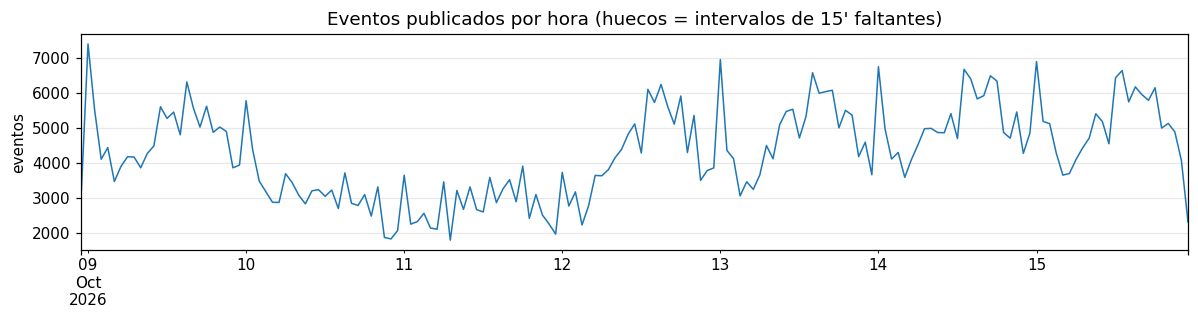

In [45]:
# Control de completitud temporal: eventos publicados por hora
serie = obt.set_index("FechaPublicacion").resample("1h").size()
fig, ax = plt.subplots(figsize=(11, 3))
serie.plot(ax=ax, lw=1)
ax.set_title("Eventos publicados por hora (huecos = intervalos de 15' faltantes)")
ax.set_ylabel("eventos"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

## 2. Limpieza

### 2.1 Nulos y ceros

Primero se perfila **toda la OBT**: porcentaje de nulos y de ceros por columna. Un cero no siempre es un faltante: hay que interpretarlo según el codebook.

In [46]:
num_cols = obt.select_dtypes("number").columns
perfil = pd.DataFrame({
    "dtype":   obt.dtypes.astype(str),
    "% nulos": obt.isna().mean() * 100,
    "% ceros": (obt[num_cols] == 0).mean().reindex(obt.columns) * 100,
}).sort_values("% nulos", ascending=False)
perfil.round(1)

,dtype,% nulos,% ceros
Actor2Type3Code,object,100.0,NaN
Actor1Type3Code,object,99.9,NaN
Actor2Religion2Code,object,99.7,NaN
Actor1Religion2Code,object,99.7,NaN
Actor2EthnicDesc,object,99.6,NaN
...,...,...,...
FechaPublicacion,datetime64[ns],0.0,NaN
DiasRetraso,int64,0.0,98.1
HoraPublicacion,int32,0.0,5.7
DiaSemana,object,0.0,NaN


ActionGeo en (0,0) 'Null Island': 0.000 %
GoldsteinScale == 0: 10.94 %  (valor válido: evento neutro)
AvgTone == 0:        1.82 %  (valor válido: tono neutro)
DiasRetraso < 0:     0.000 %  (inconsistencia temporal)


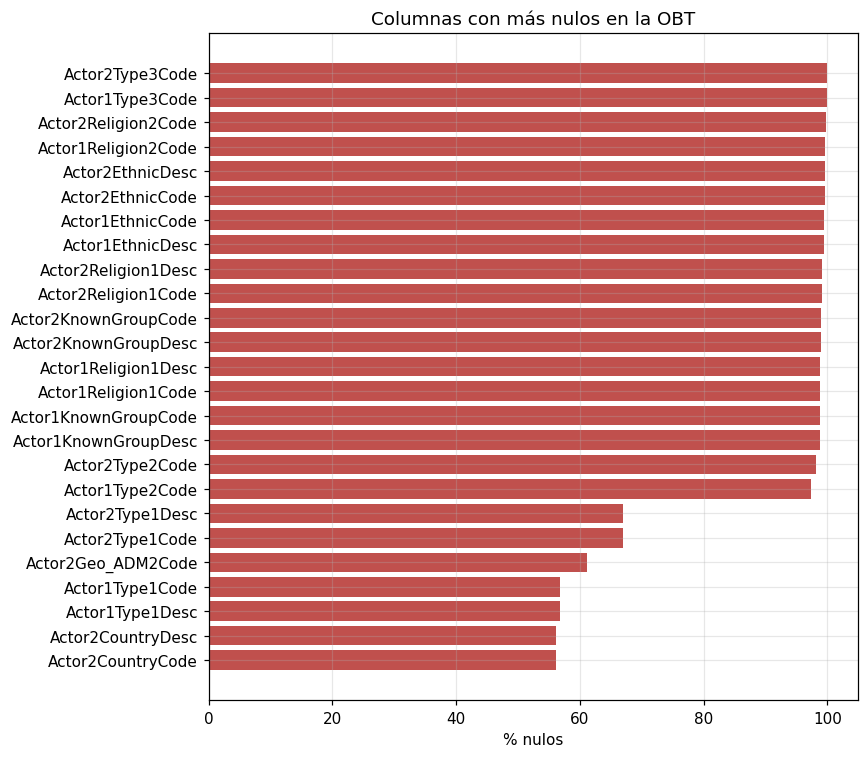

In [47]:
null_island = ((obt["ActionGeo_Lat"] == 0) & (obt["ActionGeo_Long"] == 0)).mean() * 100
print(f"ActionGeo en (0,0) 'Null Island': {null_island:.3f} %")
print(f"GoldsteinScale == 0: {(obt['GoldsteinScale'] == 0).mean()*100:.2f} %  (valor válido: evento neutro)")
print(f"AvgTone == 0:        {(obt['AvgTone'] == 0).mean()*100:.2f} %  (valor válido: tono neutro)")
print(f"DiasRetraso < 0:     {(obt['DiasRetraso'] < 0).mean()*100:.3f} %  (inconsistencia temporal)")

top = perfil["% nulos"].head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(top.index, top.values, color="#c0504d")
ax.set_xlabel("% nulos"); ax.set_title("Columnas con más nulos en la OBT")
plt.tight_layout(); plt.show()

**Selección de variables analíticas.** Para la detección de atípicos se trabaja con las variables que describen *qué* pasó, *cuánto* se cubrió, *con qué tono*, *dónde* y *quiénes*:

* **Numéricas:** `GoldsteinScale`, `AvgTone`, `NumMentions`, `NumSources`, `NumArticles`, `IsRootEvent`, `ActionGeo_Lat`, `ActionGeo_Long` (`DiasRetraso` se limpia aquí pero se trata aparte, ver "Noticias retrospectivas").
* **Categóricas:** `EventRootCode`, `QuadClass`, `Actor1CountryCode`, `Actor2CountryCode`, `ActionGeo_CountryCode`, `Actor1Type1Code`, `ActionGeo_Type`.

Las columnas con nulos masivos (`*KnownGroupCode`, `*EthnicCode`, `*Religion*`, `*Type2/3Code`, geografía de actores) quedan **descartadas** del análisis: superan ampliamente el 50 % de faltantes y su imputación inventaría información. Siguen disponibles en la OBT para interpretar los atípicos.

**Criterios de tratamiento**

| Variable | Situación | Criterio |
|---|---|---|
| `ActionGeo_Lat/Long` | nulos y (0,0) "Null Island" | (0,0) → nulo; imputación por **mediana del país** (`ActionGeo_CountryCode`); si no hay país, se **descarta** la fila (sin ubicación el evento no es localizable) |
| `GoldsteinScale` | nulos esporádicos | imputación por la **moda del `EventCode`**: en CAMEO la escala de Goldstein es función del código de evento |
| `AvgTone` | nulos esporádicos | imputación por **mediana** del `EventRootCode` |
| `NumMentions/Sources/Articles` | ceros o nulos | inconsistentes (todo evento tiene al menos 1 artículo) → **descarte** |
| `DiasRetraso` | nulo o negativo | fecha inválida → **descarte** |
| `GoldsteinScale = 0`, `AvgTone = 0` | ceros | **se conservan**: son valores neutros válidos, no faltantes |
| Atributos de Actor1/Actor2 | el actor **no existe** en el evento (`Actor1Code`/`Actor2Code` nulo) | **ausencia estructural** → `SIN_ACTOR1` / `SIN_ACTOR2`: no es un dato perdido, el evento no tiene ese actor |
| Atributos de Actor1/Actor2 | el actor existe pero falta su país o tipo | **faltante real** → `UNKNOWN`: informativo (MNAR — p.ej. actores no estatales) |
| Otras categóricas | nulos | `UNKNOWN` |

#### Ausencia estructural vs. faltante real

Un nulo en `Actor2CountryCode` puede significar dos cosas distintas: que el evento **no tiene segundo actor** (todos los campos de Actor2 vacíos, empezando por `Actor2Code`) o que el actor existe pero GDELT no pudo asignarle país. Mezclar ambos casos bajo una misma etiqueta confundiría "evento de un solo actor" con "actor no estatal".

In [48]:
estructura = pd.DataFrame({
    "actor": ["Actor1", "Actor2"],
    "% sin actor (estructural)": [obt["Actor1Code"].isna().mean() * 100, obt["Actor2Code"].isna().mean() * 100],
    "% actor sin país (faltante real)": [(obt["Actor1Code"].notna() & obt["Actor1CountryCode"].isna()).mean() * 100,
                                         (obt["Actor2Code"].notna() & obt["Actor2CountryCode"].isna()).mean() * 100],
    "contradicciones (sin código pero con país)": [int((obt["Actor1Code"].isna() & obt["Actor1CountryCode"].notna()).sum()),
                                                   int((obt["Actor2Code"].isna() & obt["Actor2CountryCode"].notna()).sum())],
}).set_index("actor")
estructura.round(2)

,% sin actor (estructural),% actor sin país (faltante real),contradicciones (sin código pero con país)
actor,,,
Actor1,9.64,34.49,0
Actor2,29.58,26.54,0


#### Auditoría de consistencia lógica

El codebook impone relaciones que deben cumplirse entre variables. Se definen como filtros booleanos y se cuentan:

| Regla | Tratamiento si se viola |
|---|---|
| `QuadClass` corresponde a `EventRootCode` (01–05 → 1, 06–09 → 2, 10–14 → 3, 15–20 → 4) | **se corrige**: es una derivación determinística del código CAMEO |
| `EventRootCode` y `EventBaseCode` son prefijos de `EventCode` | se reporta |
| `NumSources ≤ NumArticles ≤ NumMentions` | se reporta (no hay forma de saber qué conteo es el erróneo) |
| `GoldsteinScale` ∈ [−10, 10], `AvgTone` ∈ [−100, 100], latitud ∈ [−90, 90], longitud ∈ [−180, 180] | **se descarta**: valor imposible |
| `DATEADDED` no anterior a `SQLDATE` | **se descarta**: fecha imposible |
| `GoldsteinScale` única para cada `EventCode` | se reporta |

In [49]:
QUAD_POR_RAIZ = {f"{r:02d}": (1 if r <= 5 else 2 if r <= 9 else 3 if r <= 14 else 4) for r in range(1, 21)}
quad_esperada = obt["EventRootCode"].map(QUAD_POR_RAIZ)
ec = obt["EventCode"].fillna("")
lat_ok = obt["ActionGeo_Lat"].between(-90, 90) | obt["ActionGeo_Lat"].isna()
lon_ok = obt["ActionGeo_Long"].between(-180, 180) | obt["ActionGeo_Long"].isna()
reglas = {
    "QuadClass no corresponde a EventRootCode":        quad_esperada.notna() & (obt["QuadClass"] != quad_esperada),
    "EventRootCode no es prefijo de EventCode":        ec.str[:2] != obt["EventRootCode"].fillna(""),
    "EventBaseCode no es prefijo de EventCode":        ec.str[:3] != obt["EventBaseCode"].fillna("").str[:3],
    "NumSources > NumArticles":                        obt["NumSources"] > obt["NumArticles"],
    "NumArticles > NumMentions":                       obt["NumArticles"] > obt["NumMentions"],
    "GoldsteinScale fuera de [-10, 10]":               obt["GoldsteinScale"].notna() & ~obt["GoldsteinScale"].between(-10, 10),
    "AvgTone fuera de [-100, 100]":                    obt["AvgTone"].notna() & ~obt["AvgTone"].between(-100, 100),
    "Coordenadas fuera de rango":                      ~(lat_ok & lon_ok),
    "DATEADDED anterior a SQLDATE":                    obt["DiasRetraso"] < 0,
    "GoldsteinScale distinta para un mismo EventCode": obt.groupby("EventCode")["GoldsteinScale"].transform("nunique") > 1,
}
auditoria = pd.DataFrame({"eventos": {k: int(v.sum()) for k, v in reglas.items()}})
auditoria["%"] = auditoria["eventos"] / len(obt) * 100
display(auditoria.round(4))

# corrección determinística y descarte de valores imposibles
mal_quad = reglas["QuadClass no corresponde a EventRootCode"]
obt.loc[mal_quad, "QuadClass"] = quad_esperada[mal_quad]
imposible = (reglas["GoldsteinScale fuera de [-10, 10]"] | reglas["AvgTone fuera de [-100, 100]"]
             | reglas["Coordenadas fuera de rango"] | reglas["DATEADDED anterior a SQLDATE"])
obt_valida = ~imposible
print(f"QuadClass corregida: {int(mal_quad.sum())} | eventos con valores imposibles (se descartan): {int(imposible.sum())}")

,eventos,%
QuadClass no corresponde a EventRootCode,0,0.0
EventRootCode no es prefijo de EventCode,0,0.0
EventBaseCode no es prefijo de EventCode,0,0.0
NumSources > NumArticles,0,0.0
NumArticles > NumMentions,0,0.0
"GoldsteinScale fuera de [-10, 10]",0,0.0
"AvgTone fuera de [-100, 100]",0,0.0
Coordenadas fuera de rango,0,0.0
DATEADDED anterior a SQLDATE,0,0.0
GoldsteinScale distinta para un mismo EventCode,0,0.0


QuadClass corregida: 0 | eventos con valores imposibles (se descartan): 0


In [50]:
NUM = ["GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "NumArticles",
       "DiasRetraso", "IsRootEvent", "ActionGeo_Lat", "ActionGeo_Long"]
CAT = ["EventRootCode", "QuadClass", "Actor1CountryCode", "Actor2CountryCode",
       "ActionGeo_CountryCode", "Actor1Type1Code", "ActionGeo_Type"]

df = obt[["GLOBALEVENTID", "EventCode", "Actor1Code", "Actor2Code"] + NUM + CAT].copy().set_index("GLOBALEVENTID")
n0 = len(df)
bitacora = []

df = df[obt_valida.values]
bitacora.append(("Descartadas por valores imposibles (auditoría)", n0 - len(df)))

# (0,0) -> nulo
mask = (df["ActionGeo_Lat"] == 0) & (df["ActionGeo_Long"] == 0)
df.loc[mask, ["ActionGeo_Lat", "ActionGeo_Long"]] = np.nan
bitacora.append(("Null Island -> NaN", int(mask.sum())))

# coordenadas: mediana por país
for c in ["ActionGeo_Lat", "ActionGeo_Long"]:
    falt = df[c].isna().sum()
    df[c] = df[c].fillna(df.groupby("ActionGeo_CountryCode")[c].transform("median"))
    bitacora.append((f"{c} imputada por mediana del país", int(falt - df[c].isna().sum())))
antes = len(df); df = df.dropna(subset=["ActionGeo_Lat", "ActionGeo_Long"])
bitacora.append(("Descartadas sin ubicación", antes - len(df)))

# Goldstein: moda por EventCode
falt = df["GoldsteinScale"].isna().sum()
moda = df.groupby("EventCode")["GoldsteinScale"].agg(lambda s: s.mode().iat[0] if s.notna().any() else np.nan)
df["GoldsteinScale"] = df["GoldsteinScale"].fillna(df["EventCode"].map(moda))
bitacora.append(("GoldsteinScale imputada por moda del EventCode", int(falt - df["GoldsteinScale"].isna().sum())))

# AvgTone: mediana por EventRootCode
falt = df["AvgTone"].isna().sum()
df["AvgTone"] = df["AvgTone"].fillna(df.groupby("EventRootCode")["AvgTone"].transform("median"))
bitacora.append(("AvgTone imputado por mediana del EventRootCode", int(falt - df["AvgTone"].isna().sum())))

# conteos inconsistentes y fechas inválidas
antes = len(df)
cnt = ["NumMentions", "NumSources", "NumArticles"]
df = df[(df[cnt] > 0).all(axis=1) & df["DiasRetraso"].ge(0)]
df = df.dropna(subset=NUM)
bitacora.append(("Descartadas por conteos en 0 / fecha inválida / NaN residual", antes - len(df)))

# categóricas: ausencia estructural -> SIN_ACTORx ; faltante real -> UNKNOWN
df["QuadClass"] = df["QuadClass"].map(QUAD)
df["ActionGeo_Type"] = df["ActionGeo_Type"].map(GEOT)
for c, actor in [("Actor1CountryCode", "Actor1Code"), ("Actor1Type1Code", "Actor1Code"),
                 ("Actor2CountryCode", "Actor2Code")]:
    sin_actor = df[actor].isna()
    etiqueta = "SIN_" + actor[:6].upper()
    df.loc[sin_actor, c] = etiqueta
    bitacora.append((f"{c}: sin actor -> '{etiqueta}' (estructural)", int(sin_actor.sum())))
for c in CAT:
    n = df[c].isna().sum()
    df[c] = df[c].fillna("UNKNOWN").astype(str)
    bitacora.append((f"{c}: nulo -> 'UNKNOWN' (faltante real)", int(n)))

df = df.drop(columns=["EventCode", "Actor1Code", "Actor2Code"])
display(pd.DataFrame(bitacora, columns=["Acción", "Filas afectadas"]))
print(f"Filas: {n0:,} -> {len(df):,}  (descartadas {100*(1-len(df)/n0):.2f} %)")
assert df.isna().sum().sum() == 0

,Acción,Filas afectadas
0,Descartadas por valores imposibles (auditoría),0
1,Null Island -> NaN,0
2,ActionGeo_Lat imputada por mediana del país,245
3,ActionGeo_Long imputada por mediana del país,85
4,Descartadas sin ubicación,18772
5,GoldsteinScale imputada por moda del EventCode,0
6,AvgTone imputado por mediana del EventRootCode,0
7,Descartadas por conteos en 0 / fecha inválida ...,2
8,Actor1CountryCode: sin actor -> 'SIN_ACTOR1' (...,68126
9,Actor1Type1Code: sin actor -> 'SIN_ACTOR1' (es...,68126


Filas: 727,359 -> 708,585  (descartadas 2.58 %)


#### Noticias retrospectivas: una fecha inferida, no un evento raro

`DiasRetraso` (días entre la fecha del evento y la de publicación) vale 0 en ~98 % de los eventos. El resto **no se distribuye de forma continua**: se concentra en valores exactos de 7, 30, 365 y 3650 días. Esos valores no son retrasos reales sino **fechas relativas que GDELT infiere del texto** ("hace una semana", "el mes pasado", "hace un año") y redondea; típicamente son aniversarios o notas de contexto.

En una primera versión, `DiasRetraso` entraba a la matriz: al escalarla, esos pocos valores quedaban a más de 10 desvíos y **más de la mitad de los atípicos de consenso eran retrospectivas**, es decir, un artefacto de codificación y no eventos raros.

**Decisión:** se marca `es_retrospectiva` (retraso ≥ 7 días), se reporta como hallazgo de calidad de datos y se exporta en la tabla de atípicos, pero **no se usa como variable del detector**.

In [51]:
ret = obt.set_index("GLOBALEVENTID").loc[df.index, "DiasRetraso"]
df["es_retrospectiva"] = (ret >= 7).astype("int8")
tabla_ret = (ret[ret > 0].value_counts().head(8).rename("eventos").to_frame()
             .assign(**{"% del total": lambda t: 100 * t["eventos"] / len(ret)}))
display(tabla_ret.round(3))
exactos = ret.isin([7, 30, 365, 3650]).sum()
print(f"Retrospectivas (≥ 7 días): {int(df.es_retrospectiva.sum()):,} ({100 * df.es_retrospectiva.mean():.2f} %) — "
      f"de ellas en 7/30/365/3650 días exactos: {100 * exactos / max(df.es_retrospectiva.sum(), 1):.0f} %")

,eventos,% del total
DiasRetraso,,
7,4104,0.579
30,4026,0.568
365,3845,0.543
1,1504,0.212
3650,130,0.018


Retrospectivas (≥ 7 días): 12,105 (1.71 %) — de ellas en 7/30/365/3650 días exactos: 100 %


**Transformaciones previas al ACP.**

* **Conteos → percentiles.** `NumMentions`, `NumSources` y `NumArticles` tienen colas extremas y valores muy repetidos (`NumSources` = 1 en casi todos los eventos). Incluso con `log1p`, unos pocos valores quedaban a más de 10 desvíos y dominaban todas las distancias. Se reemplazan por su **percentil** (rango relativo, acotado en [0, 1]), que conserva el orden pero limita la influencia de cada evento:
  * `cobertura_pct` = percentil de `NumArticles` (cuánto se publicó),
  * `fuentes_pct` = percentil de `NumSources` (cuántos medios distintos),
  * `amplificacion_pct` = percentil de `NumMentions / NumArticles` (cuántas veces se repite el evento dentro de cada artículo).
  `NumMentions` crudo no se usa: está casi perfectamente correlacionado con `NumArticles`.
* **Tono y Goldstein en su escala original.** A diferencia de los conteos, sus valores extremos son información sustantiva (una cobertura con tono −20 o un evento de Goldstein −10 son realmente excepcionales) y su rango es acotado por definición, así que se mantienen y sólo se escalan de forma robusta.
* **Ubicación: sólo como país.** La ubicación entra al detector a través de las dummies de `ActionGeo_CountryCode` y `ActionGeo_Type`. Las coordenadas continuas (incluso convertidas a la esfera unitaria) se probaron y se descartaron: con escalado robusto, como la mayoría de las noticias son de EE. UU. y Europa, cualquier evento del hemisferio sur quedaba a más de 7 RIC de la mediana y el 95 % de los atípicos eran de tipo "lugar poco frecuente", que es una minoría geográfica y no un evento raro. Las coordenadas se conservan en la tabla exportada para el mapa.

In [52]:
asim = pd.DataFrame({"asimetría original": df[["NumArticles", "NumSources", "NumMentions"]].skew()})
df["cobertura_pct"]     = df["NumArticles"].rank(pct=True)
df["fuentes_pct"]       = df["NumSources"].rank(pct=True)
df["amplificacion_pct"] = (df["NumMentions"] / df["NumArticles"]).rank(pct=True)
asim["asimetría del percentil"] = [df[c].skew() for c in ["cobertura_pct", "fuentes_pct", "amplificacion_pct"]]
display(asim.round(2))

NUM_F = ["GoldsteinScale", "AvgTone", "cobertura_pct", "fuentes_pct", "amplificacion_pct", "IsRootEvent"]

df[NUM_F].describe().T.round(3)

,asimetría original,asimetría del percentil
NumArticles,10.67,0.05
NumSources,16.67,5.85
NumMentions,10.60,6.92


,count,mean,std,min,25%,50%,75%,max
GoldsteinScale,708585.0,0.416,4.611,-10.000,-2.000,1.000,3.400,10.000
AvgTone,708585.0,-2.100,4.180,-29.167,-4.912,-2.116,0.742,20.192
cobertura_pct,708585.0,0.500,0.284,0.077,0.289,0.563,0.743,1.000
fuentes_pct,708585.0,0.500,0.081,0.487,0.487,0.487,0.487,1.000
amplificacion_pct,708585.0,0.500,0.069,0.490,0.490,0.490,0.490,1.000
IsRootEvent,708585.0,0.517,0.500,0.000,0.000,1.000,1.000,1.000


### 2.2 Reducción de cardinalidad

Las categorías con frecuencia relativa **menor al 5 %** de la muestra se agrupan en `OTHER`. Esto evita cientos de columnas indicadoras casi vacías (p.ej. ~250 códigos de país) que dominarían la varianza del ACP y generarían falsos atípicos por pura rareza de etiqueta.

In [53]:
def agrupar_marginales(s: pd.Series, umbral: float) -> pd.Series:
    freq = s.value_counts(normalize=True)
    conservar = freq[freq >= umbral].index
    return s.where(s.isin(conservar), "OTHER")

card = []
for c in CAT:
    antes = df[c].nunique()
    df[c] = agrupar_marginales(df[c], UMBRAL_RARO)
    card.append((c, antes, df[c].nunique(), (df[c] == "OTHER").mean() * 100))
display(pd.DataFrame(card, columns=["variable", "cardinalidad original", "cardinalidad reducida", "% en OTHER"])
          .round(1).set_index("variable"))

for c in CAT:
    print(f"\n{c}:", df[c].value_counts(normalize=True).mul(100).round(1).to_dict())

,cardinalidad original,cardinalidad reducida,% en OTHER
variable,,,
EventRootCode,20,8,26.0
QuadClass,4,4,0.0
Actor1CountryCode,218,4,39.9
Actor2CountryCode,216,4,32.8
ActionGeo_CountryCode,241,4,56.8
Actor1Type1Code,33,4,29.4
ActionGeo_Type,6,5,3.1



EventRootCode: {'OTHER': 26.0, '04': 24.0, '01': 15.1, '05': 8.8, '02': 7.4, '11': 6.9, '19': 5.9, '03': 5.8}

QuadClass: {'Verbal Cooperation': 61.1, 'Verbal Conflict': 14.1, 'Material Conflict': 13.7, 'Material Cooperation': 11.0}

Actor1CountryCode: {'OTHER': 39.9, 'UNKNOWN': 33.8, 'USA': 16.7, 'SIN_ACTOR1': 9.6}

Actor2CountryCode: {'OTHER': 32.8, 'SIN_ACTOR2': 29.5, 'UNKNOWN': 25.9, 'USA': 11.8}

ActionGeo_CountryCode: {'OTHER': 56.8, 'US': 30.7, 'IN': 7.0, 'UK': 5.5}

Actor1Type1Code: {'UNKNOWN': 47.8, 'OTHER': 29.4, 'GOV': 13.2, 'SIN_ACTOR1': 9.6}

ActionGeo_Type: {'WORLDCITY': 46.3, 'COUNTRY': 21.7, 'USCITY': 16.4, 'USSTATE': 12.6, 'OTHER': 3.1}


### 2.3 Variables indicadoras (dummies)

Cada categórica se transforma en variables 0/1. Se elimina una **categoría de referencia** por variable (`OTHER` si existe; si no, la más frecuente): con todas las dummies, sus columnas suman 1 y generan colinealidad perfecta (autovalores nulos en el ACP).

In [54]:
dummies = pd.get_dummies(df[CAT], prefix=CAT, prefix_sep="=", dtype=np.uint8)
referencias = []
for c in CAT:
    ref = f"{c}=OTHER" if f"{c}=OTHER" in dummies else f"{c}={df[c].mode().iat[0]}"
    referencias.append(ref)
dummies = dummies.drop(columns=referencias)
print("Categorías de referencia eliminadas:", referencias)

X = pd.concat([df[NUM_F].astype(np.float32), dummies.astype(np.float32)], axis=1)
print(f"Matriz de características: {X.shape[0]:,} eventos × {X.shape[1]} variables")
X.head()

Categorías de referencia eliminadas: ['EventRootCode=OTHER', 'QuadClass=Verbal Cooperation', 'Actor1CountryCode=OTHER', 'Actor2CountryCode=OTHER', 'ActionGeo_CountryCode=OTHER', 'Actor1Type1Code=OTHER', 'ActionGeo_Type=OTHER']
Matriz de características: 708,585 eventos × 32 variables


,GoldsteinScale,AvgTone,cobertura_pct,fuentes_pct,amplificacion_pct,IsRootEvent,EventRootCode=01,EventRootCode=02,EventRootCode=03,EventRootCode=04,EventRootCode=05,EventRootCode=11,EventRootCode=19,QuadClass=Material Conflict,QuadClass=Material Cooperation,QuadClass=Verbal Conflict,Actor1CountryCode=SIN_ACTOR1,Actor1CountryCode=UNKNOWN,Actor1CountryCode=USA,Actor2CountryCode=SIN_ACTOR2,Actor2CountryCode=UNKNOWN,Actor2CountryCode=USA,ActionGeo_CountryCode=IN,ActionGeo_CountryCode=UK,ActionGeo_CountryCode=US,Actor1Type1Code=GOV,Actor1Type1Code=SIN_ACTOR1,Actor1Type1Code=UNKNOWN,ActionGeo_Type=COUNTRY,ActionGeo_Type=USCITY,ActionGeo_Type=USSTATE,ActionGeo_Type=WORLDCITY
GLOBALEVENTID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1327016419,-5.0,-1.413761,0.289049,0.486547,0.490159,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1327016420,7.4,0.514139,0.289049,0.486547,0.490159,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
1327016421,-2.0,-2.053140,0.289049,0.486547,0.490159,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1327016422,0.0,-2.053140,0.562774,0.486547,0.490159,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1327016423,7.4,0.514139,0.742773,0.486547,0.490159,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


#### Sensibilidad del diseño de variables

El resultado de un detector de atípicos depende de **qué variables lo alimentan y cómo se escalan**: la variable con la cola más larga termina decidiendo. Antes de fijar el diseño se probaron estas variantes (sobre una muestra de 10 horas):

| Variante | Qué dominaba el consenso | Decisión |
|---|---|---|
| z-score + `log1p` de conteos + `DiasRetraso` + coordenadas | noticias retrospectivas (62 %) e historias con muchas fuentes | descartada: artefactos de GDELT |
| `RobustScaler` + conteos en percentil + coordenadas | "lugar poco frecuente" (95 %): todo evento fuera de EE. UU./Europa | descartada: minoría geográfica, no evento raro |
| Todas las numéricas gaussianizadas (`QuantileTransformer`) | cobertura (99 %): los empates de `NumSources` no se pueden gaussianizar | descartada |
| Todas las numéricas en percentil | consenso de sólo 3 eventos; los métodos no coinciden (Jaccard ≈ 0) | descartada: sin colas no hay nada raro que detectar |
| **`RobustScaler` + conteos en percentil + tono y Goldstein originales, sin retraso ni coordenadas** | **coberturas de tono extremo e impacto Goldstein fuerte** | **adoptada** |

La lección metodológica: escalar no es un paso neutro; hay que verificar qué tipo de evento sale como atípico y si eso responde a la pregunta ("eventos raros que valga la pena investigar") o a un artefacto de la variable.

#### Variables con varianza casi nula (NZV)

Una variable casi constante no aporta información al ACP y, al estandarizarla, amplifica ruido. El **coeficiente de variación** (σ/μ) no sirve acá: `GoldsteinScale`, `AvgTone` y las coordenadas en la esfera tienen media cercana a 0 y el CV se dispara aunque la variable varíe mucho. Se usan los dos criterios de *near-zero variance* que no dependen de la escala:

* **razón de frecuencias** = frecuencia del valor más común / frecuencia del segundo (alta = casi constante),
* **% de valores distintos** sobre el total de filas.

Una variable es NZV si la razón de frecuencias supera 95/5 = 19 **y** tiene menos de 10 % de valores distintos. Con el umbral del 5 % de la sección 2.2 ninguna dummy puede superar con holgura la razón 19 (su categoría tiene al menos 5 % de frecuencia).

**Decisión: se reportan pero no se eliminan.** El criterio NZV viene del modelado predictivo, donde una variable casi constante aporta poco. En detección de atípicos es al revés: una variable que vale lo mismo en casi todos los eventos y distinto en unos pocos (p.ej. la cantidad de fuentes: casi todos los eventos tienen una sola, salvo las historias que cubren muchos medios) es justamente la que señala los eventos raros. Sólo se eliminan las variables **constantes** (varianza 0), que no aportan nada.

In [55]:
def nzv(s: pd.Series):
    vc = s.value_counts()
    razon = vc.iat[0] / vc.iat[1] if len(vc) > 1 else np.inf
    return razon, 100 * s.nunique() / len(s)

tabla_nzv = pd.DataFrame([(c, *nzv(X[c])) for c in X.columns], columns=["variable", "razón de frecuencias", "% distintos"])
tabla_nzv["NZV"] = (tabla_nzv["razón de frecuencias"] > 19) & (tabla_nzv["% distintos"] < 10)
display(tabla_nzv.sort_values("razón de frecuencias", ascending=False).head(12).round(3))
print("Variables NZV (se conservan: pueden señalar eventos raros):", tabla_nzv.loc[tabla_nzv["NZV"], "variable"].tolist() or "ninguna")
eliminar = X.columns[X.std() == 0].tolist()
X = X.drop(columns=eliminar)
NUM_F = [c for c in NUM_F if c not in eliminar]
print("Variables constantes eliminadas:", eliminar or "ninguna", f"| matriz final: {X.shape[1]} variables")

,variable,razón de frecuencias,% distintos,NZV
4,amplificacion_pct,110.541,0.023,True
3,fuentes_pct,54.088,0.003,True
1,AvgTone,19.805,6.895,True
23,ActionGeo_CountryCode=UK,17.140,0.000,False
8,EventRootCode=03,16.176,0.000,False
12,EventRootCode=19,15.813,0.000,False
11,EventRootCode=11,13.410,0.000,False
22,ActionGeo_CountryCode=IN,13.218,0.000,False
7,EventRootCode=02,12.580,0.000,False
10,EventRootCode=05,10.302,0.000,False


Variables NZV (se conservan: pueden señalar eventos raros): ['AvgTone', 'fuentes_pct', 'amplificacion_pct']
Variables constantes eliminadas: ninguna | matriz final: 32 variables


### 2.4 Reducción de la dimensionalidad: ACP

**Escalado robusto.** Se usa `RobustScaler`: a cada variable se le resta la **mediana** y se la divide por el **rango intercuartílico (RIC)**, como en el notebook de referencia de la cátedra. Frente al z-score (media y desvío) tiene dos ventajas para este problema:

1. **Resistencia a las colas:** la media y el desvío se contaminan con los propios atípicos que queremos detectar; la mediana y el RIC no.
2. **No infla las categorías poco frecuentes:** con z-score, una dummy de una categoría del 5 % vale (1 − 0,05)/0,22 ≈ 4,4 cuando está encendida, de modo que pertenecer a una categoría poco común ya empuja al evento hacia "atípico". Con `RobustScaler` las dummies quedan en 0/1 (su RIC es 0 o 1 y scikit-learn no las reescala).

Luego se ajusta el ACP con todas las componentes y se comparan cuatro criterios para la cantidad mínima de componentes:

* **Varianza acumulada** ≥ 80 % (criterio adoptado) y ≥ 90 %.
* **Kaiser generalizado:** autovalores mayores que el **promedio** de los autovalores. El "λ > 1" clásico supone variables con varianza 1, que con escalado robusto ya no se cumple.
* **Codo** del *scree plot* (máxima distancia a la recta entre el primer y el último autovalor).

In [56]:
scaler = RobustScaler()
Xs = scaler.fit_transform(X.values).astype(np.float32)
escala = pd.Series(scaler.scale_, index=X.columns)
print(f"Variables sin reescalar (RIC = 0, sobre todo dummies): {(escala == 1).sum()} de {len(escala)}")

try:
    pca = PCA(svd_solver="covariance_eigh", random_state=SEED).fit(Xs)   # eficiente con n >> p
except (ValueError, TypeError):
    pca = PCA(svd_solver="full", random_state=SEED).fit(Xs)

autoval = pca.explained_variance_
evr = pca.explained_variance_ratio_
cum = evr.cumsum()

def codo(v):
    x = np.arange(len(v)); x1, y1, x2, y2 = 0, v[0], len(v) - 1, v[-1]
    d = np.abs((y2 - y1) * x - (x2 - x1) * v + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(d.argmax()) + 1

criterios = {
    "Varianza acumulada ≥ 80 %": int(np.searchsorted(cum, 0.80) + 1),
    "Varianza acumulada ≥ 90 %": int(np.searchsorted(cum, 0.90) + 1),
    "Kaiser generalizado (λ > λ̄)": int((autoval > autoval.mean()).sum()),
    "Codo (scree plot)":         codo(autoval),
}
K = int(np.searchsorted(cum, UMBRAL_VAR) + 1)
display(pd.Series(criterios, name="componentes").to_frame())
print(f"\n==> K = {K} componentes (de {X.shape[1]} variables) explican {cum[K-1]*100:.1f} % de la varianza")

Variables sin reescalar (RIC = 0, sobre todo dummies): 29 de 32


,componentes
Varianza acumulada ≥ 80 %,12
Varianza acumulada ≥ 90 %,16
Kaiser generalizado (λ > λ̄),11
Codo (scree plot),7



==> K = 12 componentes (de 32 variables) explican 81.2 % de la varianza


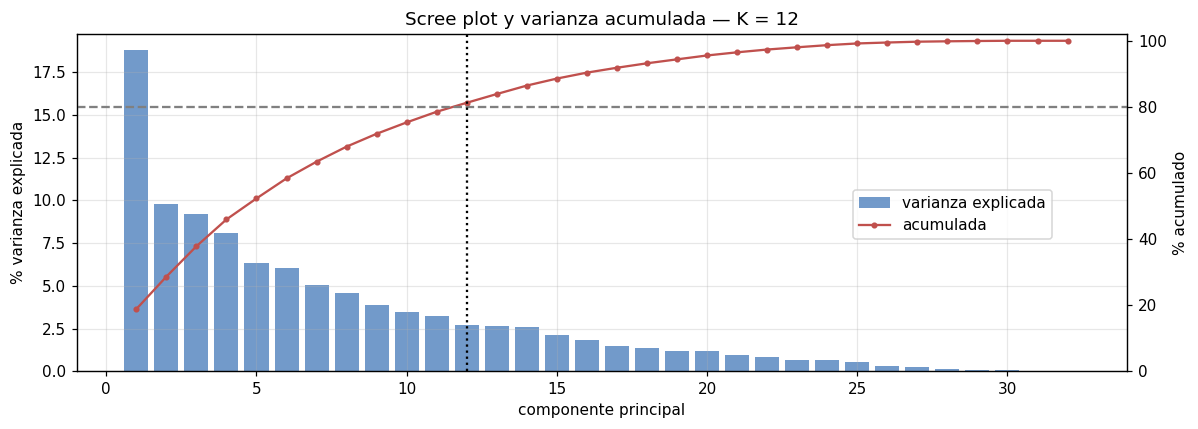

In [57]:
fig, ax1 = plt.subplots(figsize=(11, 4))
idx = np.arange(1, len(autoval) + 1)
ax1.bar(idx, evr * 100, color="#4f81bd", alpha=0.8, label="varianza explicada")
ax1.set_xlabel("componente principal"); ax1.set_ylabel("% varianza explicada")
ax2 = ax1.twinx()
ax2.plot(idx, cum * 100, "o-", color="#c0504d", ms=3, label="acumulada")
ax2.axhline(UMBRAL_VAR * 100, ls="--", color="gray")
ax2.axvline(K, ls=":", color="black")
ax2.set_ylabel("% acumulado"); ax2.set_ylim(0, 102); ax2.grid(False)
ax1.set_title(f"Scree plot y varianza acumulada — K = {K}")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
plt.tight_layout(); plt.show()

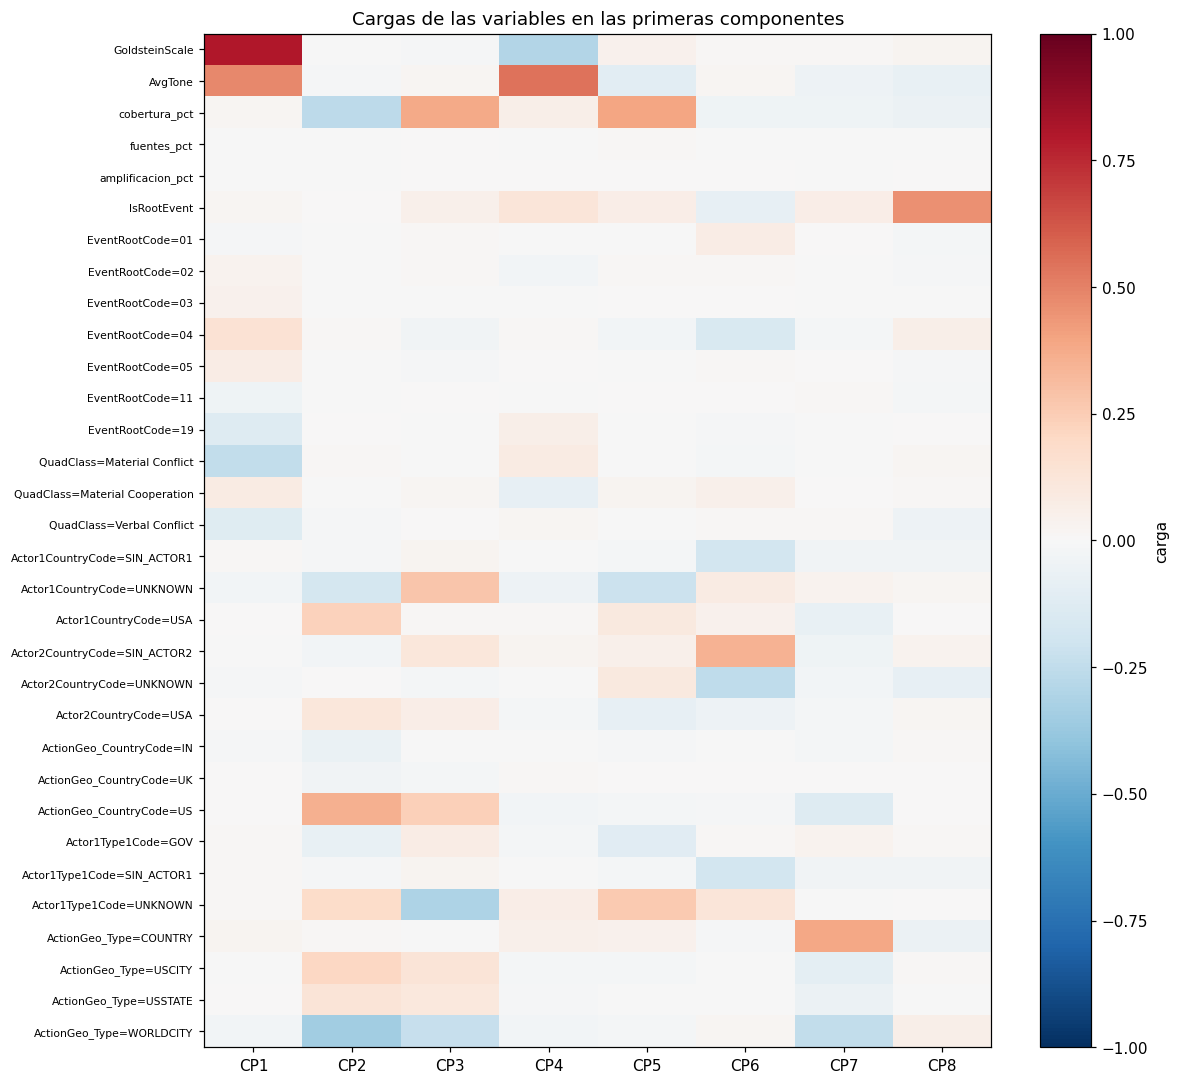

CP1 (18.8 %): GoldsteinScale (+0.80), AvgTone (+0.48), QuadClass=Material Conflict (-0.24), EventRootCode=04 (+0.14)
CP2 (9.8 %): ActionGeo_CountryCode=US (+0.35), ActionGeo_Type=WORLDCITY (-0.34), cobertura_pct (-0.27), Actor1CountryCode=USA (+0.23)
CP3 (9.2 %): cobertura_pct (+0.38), Actor1Type1Code=UNKNOWN (-0.31), Actor1CountryCode=UNKNOWN (+0.28), ActionGeo_CountryCode=US (+0.24)
CP4 (8.1 %): AvgTone (+0.54), GoldsteinScale (-0.29), IsRootEvent (+0.12), QuadClass=Material Conflict (+0.08)


In [58]:
# Cargas (loadings) de las primeras componentes: correlación variable-componente
nc = min(K, 8)
loadings = pd.DataFrame(pca.components_[:nc].T * np.sqrt(autoval[:nc]),
                        index=X.columns, columns=[f"CP{i+1}" for i in range(nc)])
fig, ax = plt.subplots(figsize=(1.0 * nc + 3, 0.28 * len(X.columns) + 1))
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(nc)); ax.set_xticklabels(loadings.columns)
ax.set_yticks(range(len(X.columns))); ax.set_yticklabels(X.columns, fontsize=7)
ax.grid(False); plt.colorbar(im, ax=ax, label="carga")
ax.set_title("Cargas de las variables en las primeras componentes")
plt.tight_layout(); plt.show()

for c in loadings.columns[:4]:
    top = loadings[c].abs().sort_values(ascending=False).head(4).index
    print(f"{c} ({evr[int(c[2:])-1]*100:.1f} %):", ", ".join(f"{v} ({loadings.at[v, c]:+.2f})" for v in top))

**Interpretación.** Las cargas permiten nombrar las componentes: típicamente una componente de **cobertura mediática** (`cobertura_pct`, `fuentes_pct`, `amplificacion_pct`), una de **conflicto vs. cooperación** (GoldsteinScale, QuadClass, EventRootCode, AvgTone), y componentes **geográficas** (país del ActionGeo). Al trabajar con una matriz mixta (continuas + dummies), la varianza se reparte entre muchas direcciones, por lo que K suele ser una fracción moderada de las variables originales; aun así el ACP elimina las direcciones redundantes y de ruido.

### 2.5 Detección de eventos atípicos multivariantes

Se siguen las familias de métodos del notebook de referencia de la cátedra (*Cardiotocography outliers*), aplicadas sobre el espacio reducido del ACP (la primera de las "otras ideas" que propone ese notebook):

| Familia | Método | Score | Criterio de marcado |
|---|---|---|---|
| Distancia global | **Z-score** de la distancia euclídea al centroide | $z(d_i)$ | $z > 3$ |
| Distancia global | **Tukey fences** sobre la misma distancia | $d_i$ | $d_i > Q_3 + 2\cdot IQR$ |
| ACP — espacio reducido | **T² de Hotelling** (Mahalanobis en las K componentes) | $T^2_i=\sum_k z_{ik}^2/\lambda_k$ | $\chi^2_{0.999}(K)$ |
| ACP — reconstrucción | **SPE / Q** (error fuera del subespacio) | $\lVert x_i-\hat x_i\rVert^2$ | aproximación de Box |
| Agrupamiento | **K-Means**: distancia al centroide de su grupo | $d(x_i, c_{g(i)})$ | 1 % superior |
| Proximidad | **k-NN**: distancia media a los k vecinos | $\bar d_k$ | 1 % superior |
| Densidad | **LOF** (densidad local relativa) | LOF | 1 % superior |
| Densidad | **DBSCAN**: ruido (lejos de todo punto núcleo) | — | etiqueta de ruido |
| Subespacios | **Isolation Forest** | profundidad media de aislamiento | 1 % superior |
| Red neuronal | **Autoencoder**: error de reconstrucción | MSE por evento | 1 % superior |

**Diferencias respecto del notebook de referencia.**
* El CTG tiene etiquetas (NSP), por eso allí se evalúa con matriz de confusión, *recall* y precisión. **GDELT no tiene etiquetas de "evento raro"**: la validación es por **acuerdo entre métodos** (índice de Jaccard) y **consenso por mayoría de votos**, más la inspección manual de las fuentes.
* El CTG tiene 2.126 registros; aquí hay ~10⁶ eventos. Los métodos de vecindad (k-NN, LOF, DBSCAN) son O(n²): se ajustan sobre una **muestra de referencia** de `N_REF` eventos y se **evalúan sobre todos** (modo *novelty*). K-Means usa la variante *MiniBatch*.
* Los métodos de score continuo usan el mismo corte (`TOP_FRAC` = 1 %, como el K-Means del notebook de referencia) para que los votos sean comparables.

In [59]:
rng = np.random.default_rng(SEED)
Z = pca.transform(Xs)[:, :K].astype(np.float64)
lam = autoval[:K]
n = len(Z)
idx_ref = rng.choice(n, size=min(n, N_REF), replace=False)       # muestra de referencia para métodos O(n²)
Z_ref = Z[idx_ref]

scores, flags, familia = {}, {}, {}
def registrar(nombre, fam, score, flag):
    scores[nombre], flags[nombre], familia[nombre] = np.asarray(score, float), np.asarray(flag, bool), fam
    print(f"{nombre:<20} {fam:<24} marcados: {flags[nombre].sum():>9,}  ({flags[nombre].mean()*100:.2f} %)")

def top(score, frac=TOP_FRAC):
    return score > np.quantile(score, 1 - frac)

#### 2.5.1 Métodos por distancia global

Distancia euclídea de cada evento al vector promedio (en el espacio de componentes), convertida a Z-score. Antes de usar el corte de 3 desvíos conviene preguntarse **en qué supuesto se apoya**: que las distancias sean normales. Se verifica con curtosis y la prueba de Anderson-Darling (sobre una muestra, ya que con n ≈ 10⁶ cualquier desvío mínimo resulta significativo). Si no hay normalidad, las **Tukey fences** (basadas en cuartiles) son más robustas.

Curtosis (exceso) de las distancias: 0.89  (normal = 0)
Anderson-Darling: estadístico = 30.64 | valor crítico al 5 % = 0.786 -> NO normal
Z-score              Distancia global         marcados:     4,164  (0.59 %)
Tukey                Distancia global         marcados:     4,051  (0.57 %)


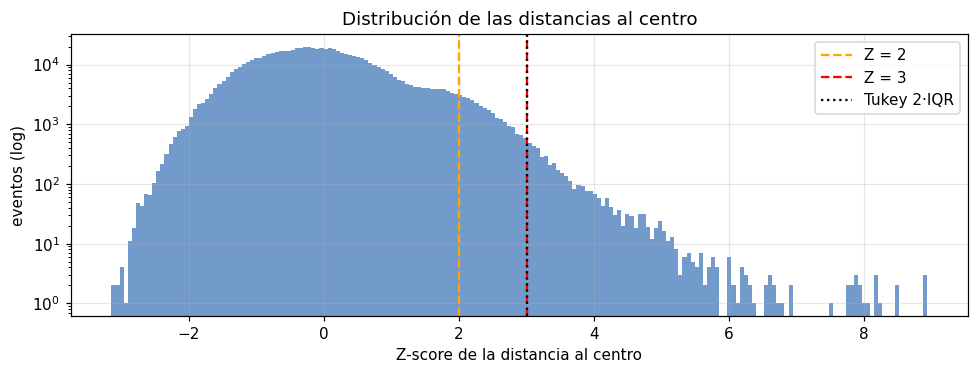

In [60]:
dist_centro = np.linalg.norm(Z - Z.mean(axis=0), axis=1)
z_dist = zscore(dist_centro)

print(f"Curtosis (exceso) de las distancias: {pd.Series(z_dist).kurtosis():.2f}  (normal = 0)")
ad = anderson(rng.choice(z_dist, size=min(n, 5_000), replace=False), dist="norm")
print(f"Anderson-Darling: estadístico = {ad.statistic:.2f} | valor crítico al 5 % = {ad.critical_values[2]:.3f} -> "
      + ("NO normal" if ad.statistic > ad.critical_values[2] else "compatible con normal"))

q1, q3 = np.percentile(dist_centro, [25, 75])
lim_tukey = q3 + 2 * (q3 - q1)

registrar("Z-score", "Distancia global", z_dist, z_dist > 3)
registrar("Tukey", "Distancia global", dist_centro, dist_centro > lim_tukey)

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(z_dist, bins=200, color="#4f81bd", alpha=0.8)
for x, c in [(2, "orange"), (3, "red")]:
    ax.axvline(x, color=c, ls="--", label=f"Z = {x}")
ax.axvline((lim_tukey - dist_centro.mean()) / dist_centro.std(), color="black", ls=":", label="Tukey 2·IQR")
ax.set_yscale("log"); ax.set_xlabel("Z-score de la distancia al centro"); ax.set_ylabel("eventos (log)")
ax.set_title("Distribución de las distancias al centro"); ax.legend()
plt.tight_layout(); plt.show()

#### 2.5.2 Modelo ACP: espacio reducido (T²) y reconstrucción (SPE)

* **T² de Hotelling**: a diferencia de la distancia euclídea anterior, pondera cada componente por su autovalor (distancia de Mahalanobis). Detecta combinaciones **extremas pero coherentes** con la estructura (p.ej. cobertura masiva). Límite $\chi^2_{0.999}(K)$.
* **SPE / Q**: error cuadrático de reconstrucción desde las K componentes. Detecta eventos que **rompen la correlación** habitual (p.ej. tono muy positivo en un conflicto material). Límite de Box $g\,\chi^2_{\alpha}(h)$, con $g=\mathrm{var}(Q)/(2\bar Q)$ y $h=2\bar Q^2/\mathrm{var}(Q)$.

In [61]:
T2 = (Z**2 / lam).sum(axis=1)
lim_T2 = chi2.ppf(ALPHA, K)

Xc = Xs.astype(np.float64) - pca.mean_
SPE = np.clip((Xc**2).sum(axis=1) - (Z**2).sum(axis=1), 0, None)   # ||x||² = ||z||² + ||e||²
m, v = SPE.mean(), SPE.var()
g, h = v / (2 * m), 2 * m**2 / v
lim_SPE = g * chi2.ppf(ALPHA, h)

print(f"Límite T² = {lim_T2:,.2f} | Límite SPE = {lim_SPE:,.2f}")
registrar("T² Hotelling", "ACP espacio reducido", T2, T2 > lim_T2)
registrar("SPE (Q)", "ACP reconstrucción", SPE, SPE > lim_SPE)

Límite T² = 32.91 | Límite SPE = 3.63
T² Hotelling         ACP espacio reducido     marcados:       265  (0.04 %)
SPE (Q)              ACP reconstrucción       marcados:       163  (0.02 %)


#### 2.5.3 Modelos basados en agrupamiento: K-Means

En vez de medir contra el centro de toda la masa de datos, se agrupan los eventos y se mide la distancia de cada uno **al centroide de su propio grupo**. Un evento lejos de todos los perfiles típicos de cobertura es candidato a atípico.

In [62]:
kmeans = MiniBatchKMeans(n_clusters=K_CLUSTERS, random_state=SEED, batch_size=8192, n_init=5).fit(Z)
dist_km = np.linalg.norm(Z - kmeans.cluster_centers_[kmeans.labels_], axis=1)

ss_total = ((Z - Z.mean(0))**2).sum()
ss_within = (dist_km**2).sum()
print(f"Varianza explicada por los grupos (SSB/SST): {1 - ss_within/ss_total:.1%}")
print("Tamaño de los grupos:", np.bincount(kmeans.labels_).tolist())
registrar("K-Means", "Agrupamiento", dist_km, top(dist_km))

Varianza explicada por los grupos (SSB/SST): 43.8%
Tamaño de los grupos: [72274, 88151, 47614, 85886, 84012, 80524, 61976, 92096, 47484, 48568]
K-Means              Agrupamiento             marcados:     7,085  (1.00 %)


#### 2.5.4 Modelos basados en proximidad: k-NN

Grado de aislamiento = distancia media a los k vecinos más cercanos. No asume un centroide: un evento es raro si **no tiene vecinos parecidos**, aunque esté cerca del centro global.

In [63]:
nn = NearestNeighbors(n_neighbors=K_VECINOS + 1).fit(Z_ref)
d_vec, _ = nn.kneighbors(Z)
en_ref = np.zeros(n, dtype=bool); en_ref[idx_ref] = True
# los puntos de la muestra de referencia se encuentran a sí mismos (distancia 0): se descarta ese vecino
knn_score = np.where(en_ref, d_vec[:, 1:].mean(axis=1), d_vec[:, :-1].mean(axis=1))
registrar("k-NN", "Proximidad", knn_score, top(knn_score))

k-NN                 Proximidad               marcados:     7,086  (1.00 %)


#### 2.5.5 Modelos basados en densidad: LOF y DBSCAN

* **LOF** compara la densidad local de cada evento con la de sus vecinos: detecta atípicos *locales* (raros dentro de su vecindario aunque no lo sean globalmente).
* **DBSCAN** no asume grupos esféricos: los puntos que no alcanzan `min_samples` vecinos dentro de un radio `eps` son **ruido**. El `eps` se elige con el **gráfico de k-distancias** (codo). Como DBSCAN no puede evaluar puntos nuevos, se ajusta sobre la muestra de referencia y luego un evento se considera ruido si su distancia al punto núcleo más cercano supera `eps`.

LOF                  Densidad                 marcados:     7,086  (1.00 %)


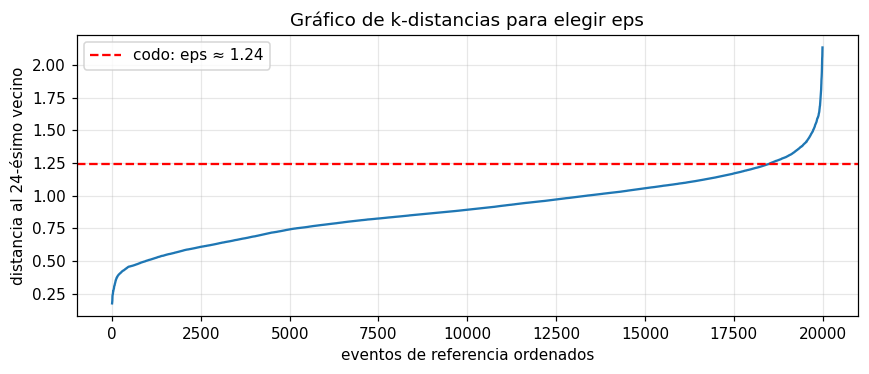

DBSCAN en la muestra: 1 grupos, 0.77 % ruido
DBSCAN               Densidad                 marcados:     5,491  (0.77 %)


In [64]:
lof = LocalOutlierFactor(n_neighbors=K_VECINOS, novelty=True).fit(Z_ref)
lof_score = -lof.score_samples(Z)                       # mayor = menos denso que sus vecinos
registrar("LOF", "Densidad", lof_score, top(lof_score))

# DBSCAN: elección de eps con el gráfico de k-distancias
MIN_SAMPLES = 2 * K
d_k, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Z_ref).kneighbors(Z_ref)
k_dist = np.sort(d_k[:, -1])
eps = float(k_dist[codo(k_dist) - 1])

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(k_dist, lw=1.5)
ax.axhline(eps, color="red", ls="--", label=f"codo: eps ≈ {eps:.2f}")
ax.set_xlabel("eventos de referencia ordenados"); ax.set_ylabel(f"distancia al {MIN_SAMPLES}-ésimo vecino")
ax.set_title("Gráfico de k-distancias para elegir eps"); ax.legend()
plt.tight_layout(); plt.show()

db = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit(Z_ref)
n_grupos = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
print(f"DBSCAN en la muestra: {n_grupos} grupos, {np.mean(db.labels_ == -1)*100:.2f} % ruido")

nucleos = Z_ref[db.core_sample_indices_]
d_nucleo = NearestNeighbors(n_neighbors=1).fit(nucleos).kneighbors(Z)[0][:, 0]
registrar("DBSCAN", "Densidad", d_nucleo, d_nucleo > eps)

#### 2.5.6 Modelos basados en subespacios: Isolation Forest

Construye árboles que eligen al azar una variable y un punto de corte; los atípicos quedan **aislados en pocas particiones** (profundidad media baja). No supone normalidad ni usa distancias.

In [65]:
muestra_if = rng.choice(n, size=min(n, 300_000), replace=False)
iso = IsolationForest(n_estimators=300, max_samples=512, random_state=SEED, n_jobs=-1).fit(Z[muestra_if])
if_score = -iso.score_samples(Z)                        # mayor = más fácil de aislar
registrar("Isolation Forest", "Subespacios", if_score, top(if_score))

Isolation Forest     Subespacios              marcados:     7,085  (1.00 %)


#### 2.5.7 Autoencoder: error de reconstrucción

Versión no lineal de la idea del SPE: una red densa comprime las variables escaladas a un **espacio latente** de pocas dimensiones y las reconstruye. Un evento que la red **no puede reconstruir bien** no se parece a lo que aprendió como típico. Como en GDELT no hay etiquetas, se entrena con una muestra de todos los eventos (los atípicos son una fracción ínfima y casi no influyen en el patrón aprendido).

| capa | salida |
|---|---|
| `Linear(p, 32)` + ReLU | 32 |
| `Linear(32, 16)` + ReLU | 16 |
| `Linear(16, DIM_LATENTE)` | espacio latente |
| decoder: camino inverso | p |

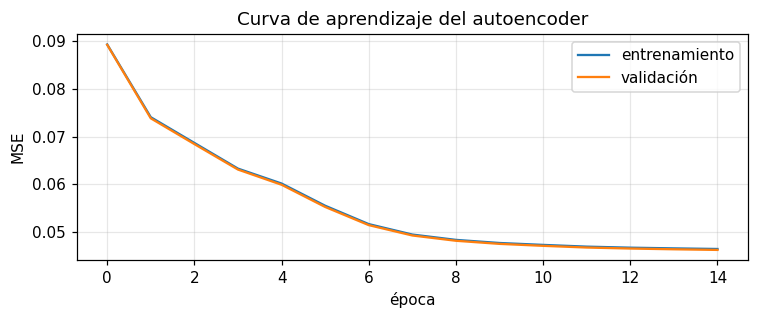

Autoencoder          Red neuronal             marcados:     7,086  (1.00 %)


In [66]:
try:
    import torch
    import torch.nn as nn_t
except ImportError:
    torch = None
    print("PyTorch no disponible: se omite el autoencoder (en Colab viene instalado).")

if torch is not None:
    torch.manual_seed(SEED)
    p = Xs.shape[1]

    class Autoencoder(nn_t.Module):
        def __init__(self, dim):
            super().__init__()
            self.encoder = nn_t.Sequential(nn_t.Linear(p, 32), nn_t.ReLU(), nn_t.Linear(32, 16), nn_t.ReLU(),
                                           nn_t.Linear(16, dim))
            self.decoder = nn_t.Sequential(nn_t.Linear(dim, 16), nn_t.ReLU(), nn_t.Linear(16, 32), nn_t.ReLU(),
                                           nn_t.Linear(32, p))
        def forward(self, x):
            return self.decoder(self.encoder(x))

    idx_ae = rng.choice(n, size=min(n, 300_000), replace=False)
    corte = int(0.9 * len(idx_ae))
    X_tr = torch.tensor(Xs[idx_ae[:corte]]); X_va = torch.tensor(Xs[idx_ae[corte:]])

    ae = Autoencoder(DIM_LATENTE)
    opt = torch.optim.Adam(ae.parameters(), lr=1e-3)
    perdida = nn_t.MSELoss()
    hist = []
    for epoca in range(EPOCAS_AE):
        ae.train()
        for lote in torch.randperm(len(X_tr)).split(1024):
            opt.zero_grad()
            l = perdida(ae(X_tr[lote]), X_tr[lote])
            l.backward(); opt.step()
        ae.eval()
        with torch.no_grad():
            hist.append((perdida(ae(X_tr[:50_000]), X_tr[:50_000]).item(), perdida(ae(X_va), X_va).item()))

    fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot([a for a, _ in hist], label="entrenamiento"); ax.plot([b for _, b in hist], label="validación")
    ax.set_xlabel("época"); ax.set_ylabel("MSE"); ax.set_title("Curva de aprendizaje del autoencoder"); ax.legend()
    plt.tight_layout(); plt.show()

    with torch.no_grad():
        error_rec = np.concatenate([((ae(torch.tensor(b)) - torch.tensor(b))**2).mean(1).numpy()
                                    for b in np.array_split(Xs, max(1, n // 100_000))])
    registrar("Autoencoder", "Red neuronal", error_rec, top(error_rec))

#### 2.5.8 Comparación de métodos y consenso

Sin etiquetas no hay *recall* ni precisión. Se compara:
* cuántos eventos marca cada método,
* el **acuerdo entre métodos** (índice de Jaccard: |A∩B| / |A∪B|): métodos de familias distintas que coinciden refuerzan la evidencia,
* el **consenso**: un evento es atípico si lo marca **la mayoría** de los métodos. El ranking final es el promedio de los percentiles de todos los scores.

,familia,marcados,% marcados,Jaccard con consenso
Z-score,Distancia global,4164,0.588,0.205
Tukey,Distancia global,4051,0.572,0.210
T² Hotelling,ACP espacio reducido,265,0.037,0.310
SPE (Q),ACP reconstrucción,163,0.023,0.000
K-Means,Agrupamiento,7085,1.000,0.121
k-NN,Proximidad,7086,1.000,0.119
LOF,Densidad,7086,1.000,0.017
DBSCAN,Densidad,5491,0.775,0.154
Isolation Forest,Subespacios,7085,1.000,0.110
Autoencoder,Red neuronal,7086,1.000,0.008


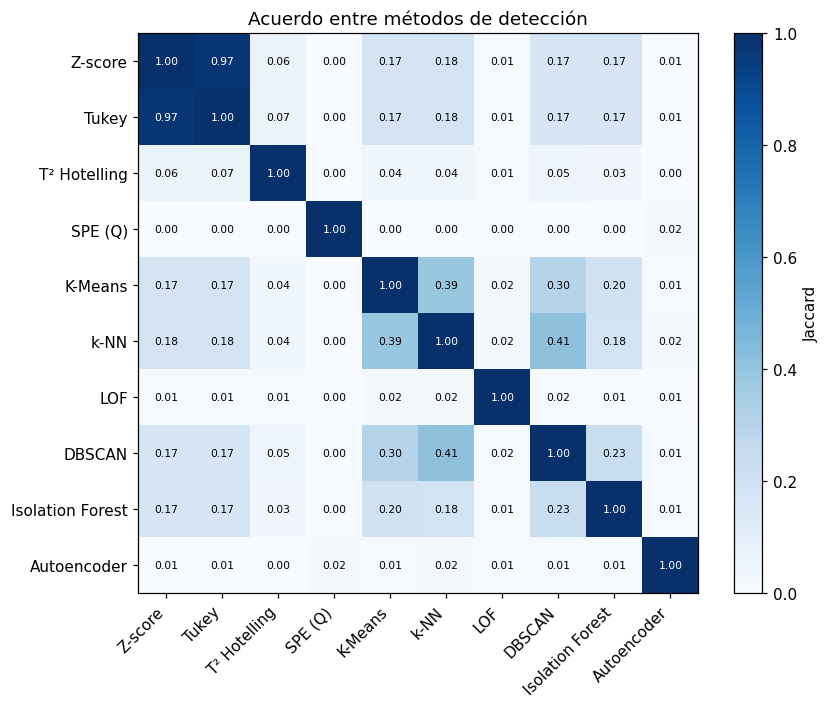

,eventos
votos,
0,678182
1,21012
2,4648
3,2311
4,1063
5,515
6,567
7,218
8,55



==> Atípicos de consenso (≥ 6 de 10 métodos): 854 (0.121 %)


In [67]:
nombres = list(flags)
F = pd.DataFrame(flags, index=df.index)
S = pd.DataFrame(scores, index=df.index)

res = pd.concat([S.add_prefix("score_"), F.add_prefix("flag_")], axis=1)
res["votos"] = F.sum(axis=1)
VOTOS_MIN = len(nombres) // 2 + 1
res["score_atipico"] = S.rank(pct=True).mean(axis=1)
res["atipico"] = res["votos"] >= VOTOS_MIN

jac = pd.DataFrame(index=nombres, columns=nombres, dtype=float)
for a in nombres:
    for b in nombres:
        union = (F[a] | F[b]).sum()
        jac.loc[a, b] = (F[a] & F[b]).sum() / union if union else np.nan

resumen = pd.DataFrame({
    "familia": pd.Series(familia),
    "marcados": F.sum(),
    "% marcados": F.mean() * 100,
    "Jaccard con consenso": [(F[m] & res.atipico).sum() / max((F[m] | res.atipico).sum(), 1) for m in nombres],
}, index=nombres)
display(resumen.round(3))

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(jac.values.astype(float), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(nombres))); ax.set_xticklabels(nombres, rotation=45, ha="right")
ax.set_yticks(range(len(nombres))); ax.set_yticklabels(nombres)
for i in range(len(nombres)):
    for j in range(len(nombres)):
        ax.text(j, i, f"{jac.iat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                color="white" if jac.iat[i, j] > 0.5 else "black")
ax.grid(False); plt.colorbar(im, ax=ax, label="Jaccard")
ax.set_title("Acuerdo entre métodos de detección")
plt.tight_layout(); plt.show()

display(res["votos"].value_counts().sort_index().rename("eventos").to_frame())
print(f"\n==> Atípicos de consenso (≥ {VOTOS_MIN} de {len(nombres)} métodos): "
      f"{res.atipico.sum():,} ({res.atipico.mean()*100:.3f} %)")

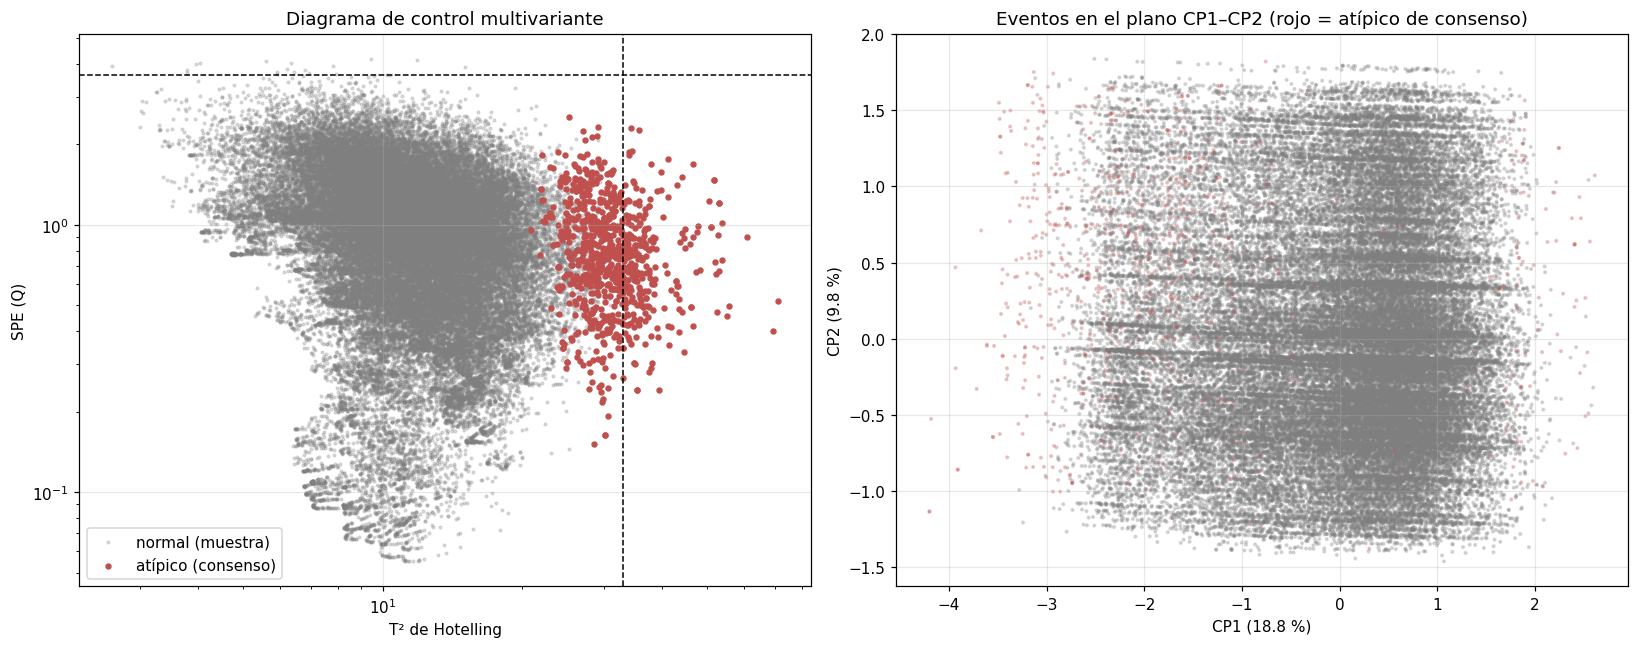

In [68]:
# Diagrama de control T² vs SPE y plano CP1–CP2 (muestra + todos los atípicos de consenso)
sel = np.union1d(rng.choice(n, size=min(n, 60_000), replace=False), np.flatnonzero(res["atipico"].values))
r = res.iloc[sel]
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
ax = axes[0]
ax.scatter(r["score_T² Hotelling"][~r.atipico], r["score_SPE (Q)"][~r.atipico],
           s=3, alpha=0.25, color="#7f7f7f", label="normal (muestra)")
ax.scatter(r["score_T² Hotelling"][r.atipico], r["score_SPE (Q)"][r.atipico], s=10, color="#c0504d",
           label="atípico (consenso)")
ax.axvline(lim_T2, ls="--", color="black", lw=1); ax.axhline(lim_SPE, ls="--", color="black", lw=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("T² de Hotelling"); ax.set_ylabel("SPE (Q)"); ax.set_title("Diagrama de control multivariante")
ax.legend()

ax = axes[1]
ax.scatter(Z[sel, 0], Z[sel, 1], s=3, alpha=0.25, c=np.where(res["atipico"].values[sel], "#c0504d", "#7f7f7f"))
ax.set_xlabel(f"CP1 ({evr[0]*100:.1f} %)"); ax.set_ylabel(f"CP2 ({evr[1]*100:.1f} %)")
ax.set_title("Eventos en el plano CP1–CP2 (rojo = atípico de consenso)")
plt.tight_layout(); plt.show()

#### Explicación de cada atípico y exportación

Para que la tabla sea accionable por un periodista, cada atípico lleva:
* las 3 variables con mayor **valor escalado** en módulo (qué tiene de extremo, en unidades de RIC),
* las 3 variables con mayor **residuo** de reconstrucción (qué correlación rompe),
* un **tipo** según la familia de la variable dominante (cobertura, tono, impacto Goldstein, lugar, actores, tipo de evento) o "combinación inusual" si lo marcó el SPE,
* la marca `es_retrospectiva`,

junto con **todos los atributos de la OBT**. Como un mismo artículo genera varios eventos GDELT, además se exporta una tabla **agrupada por noticia** (`SOURCEURL`), que es la unidad que un periodista investiga.

In [69]:
ids = res.index[res["atipico"]]
pos = res.index.get_indexer(ids)
cols = np.array(X.columns)

zs = Xs[pos]
resid = Xc[pos] - Z[pos] @ pca.components_[:K]

def top3(mat):
    idx = np.argsort(-np.abs(mat), axis=1)[:, :3]
    return [", ".join(f"{cols[j]} ({fila[j]:+.1f})" for j in fila_idx) for fila, fila_idx in zip(mat, idx)]

FAMILIAS = {"cobertura": ("cobertura_pct", "fuentes_pct", "amplificacion_pct"), "tono": ("AvgTone",),
            "impacto Goldstein": ("GoldsteinScale",), "lugar": ("Geo_", "ActionGeo_"),
            "actores": ("Actor1", "Actor2"), "tipo de evento": ("EventRootCode", "QuadClass", "IsRootEvent")}
def familia_de(col):
    return next((f for f, pref in FAMILIAS.items() if col.startswith(pref)), "otra")

dominante = cols[np.argmax(np.abs(zs), axis=1)]
tipo = [("combinación inusual (SPE)" if spe else familia_de(c))
        for c, spe in zip(dominante, res.loc[ids, "flag_SPE (Q)"].values)]
explic = pd.DataFrame({"tipo_atipico": tipo, "Top_variables": top3(zs), "Top_residuo": top3(resid),
                       "es_retrospectiva": df.loc[ids, "es_retrospectiva"].values}, index=ids)

COLS_OBT = ["GLOBALEVENTID", "FechaEvento", "FechaPublicacion", "DiasRetraso",
            "Actor1Name", "Actor1CountryCode", "Actor1CountryDesc", "Actor2Name", "Actor2CountryCode", "Actor2CountryDesc",
            "EventCode", "EventDesc", "EventRootCode", "EventRootDesc", "QuadClassDesc",
            "GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "NumArticles", "IsRootEvent",
            "ActionGeo_FullName", "ActionGeo_CountryCode", "ActionGeo_CountryDesc", "ActionGeo_Lat", "ActionGeo_Long",
            "Dominio", "SOURCEURL"]

atipicos = (obt[COLS_OBT].set_index("GLOBALEVENTID").loc[ids]
            .join(res.loc[ids, [c for c in res.columns if c != "atipico"]])
            .join(explic)
            .sort_values(["votos", "score_atipico"], ascending=False)
            .reset_index())
atipicos.insert(1, "ranking", np.arange(1, len(atipicos) + 1))

atipicos.to_parquet(ATI_PATH, engine="pyarrow", compression="snappy", index=False)
atipicos.to_csv(ATI_PATH.with_suffix(".csv"), index=False)

# Agrupación por noticia: una fila por artículo, con su evento más atípico como representante
historias = (atipicos.sort_values("score_atipico", ascending=False)
             .groupby("SOURCEURL", sort=False)
             .agg(eventos_atipicos=("GLOBALEVENTID", "size"), score_max=("score_atipico", "max"),
                  votos_max=("votos", "max"), tipo_atipico=("tipo_atipico", "first"),
                  evento=("EventDesc", "first"), actor1=("Actor1Name", "first"), actor2=("Actor2Name", "first"),
                  lugar=("ActionGeo_FullName", "first"), fecha_evento=("FechaEvento", "first"),
                  tono=("AvgTone", "first"), goldstein=("GoldsteinScale", "first"), articulos=("NumArticles", "max"),
                  es_retrospectiva=("es_retrospectiva", "max"))
             .sort_values(["votos_max", "score_max"], ascending=False).reset_index())
historias.insert(0, "ranking", np.arange(1, len(historias) + 1))
HIS_PATH = DATA_DIR / "gdelt_atipicos_por_noticia.csv"
historias.to_csv(HIS_PATH, index=False)

print(f"Tabla de atípicos (eventos): {ATI_PATH} — {len(atipicos):,} eventos")
print(f"Tabla de atípicos por noticia: {HIS_PATH} — {len(historias):,} noticias")
print(f"Retrospectivas entre los atípicos: {100 * atipicos['es_retrospectiva'].mean():.1f} %")
display(atipicos["tipo_atipico"].value_counts().rename("atípicos").to_frame())
historias.head(20)

Tabla de atípicos (eventos): /content/gdelt_tp4/gdelt_atipicos.parquet — 854 eventos
Tabla de atípicos por noticia: /content/gdelt_tp4/gdelt_atipicos_por_noticia.csv — 393 noticias
Retrospectivas entre los atípicos: 2.2 %


,atípicos
tipo_atipico,
tono,788
impacto Goldstein,66


,ranking,SOURCEURL,eventos_atipicos,score_max,votos_max,tipo_atipico,evento,actor1,actor2,lugar,fecha_evento,tono,goldstein,articulos,es_retrospectiva
0,1,https://www.kentuckynewera.com/news/courts/art...,12,0.986459,9,tono,"Return, release, not specified below",CHRISTIAN,UNITED STATES,"Tennessee, United States",2026-10-10,-23.372781,7.0,5,0
1,2,https://www.breakingnews.ie/world/russell-bran...,1,0.984002,9,tono,Sexually assault,UNITED KINGDOM,None,United Kingdom,2026-10-14,-24.324324,-9.0,2,0
2,3,http://www.cecildaily.com/ap/world/tear-gas-fi...,4,0.979726,9,tono,"Use conventional military force, not specified...",GOVERNMENT,ALBANIA,"Tirana, Tirane, Albania",2026-10-15,-29.166667,-10.0,20,0
3,4,http://www.dailyadvance.com/news/world/tear-ga...,3,0.979726,9,tono,"Use conventional military force, not specified...",GOVERNMENT,ALBANIA,"Tirana, Tirane, Albania",2026-10-14,-29.166667,-10.0,20,0
4,5,https://www.kxii.com/2026/10/12/woman-arrested...,1,0.967465,9,tono,"Arrest, detain, or charge with legal action",PARIS,TEXAS,"Paris, France (general), France",2026-10-12,-28.358209,-5.0,8,0
5,6,https://www.israelnationalnews.com/flashes/695326,6,0.953505,9,tono,"Threaten to use military force, not specified ...",DUTCH,TERRORIST,Netherlands,2026-10-14,-28.571429,-7.0,6,0
6,7,https://www.israelnationalnews.com/flashes/695408,2,0.948144,9,tono,"Use conventional military force, not specified...",TURKISH,TURKEY,Turkey,2026-10-15,-26.666667,-10.0,6,0
7,8,https://www.ugandaonline.net/news/2026-10-14--...,1,0.946222,9,tono,"Threaten, not specified below",None,UGANDA,Uganda,2026-10-14,-27.906977,-4.4,10,0
8,9,https://coast1009.com/uncategorized/severe-tur...,2,0.922768,9,tono,Make a visit,MIAMI,MIAMI,"Miami, Florida, United States",2026-10-10,-29.032258,1.9,5,0
9,10,https://www.baltimoresun.com/2026/10/12/baltim...,15,0.984860,8,tono,"Use conventional military force, not specified...",AMIT,CHINA,China,2026-10-12,-19.158200,-10.0,10,0


#### Perfil de los atípicos

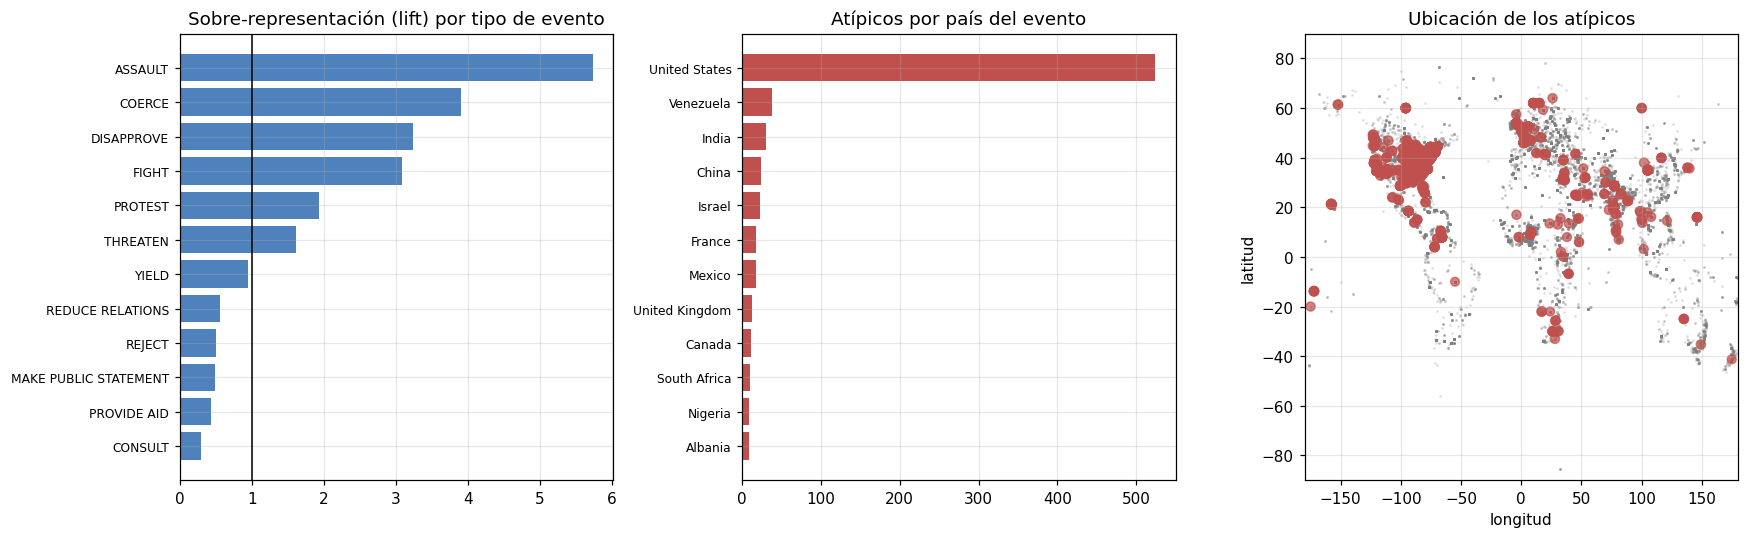

,todos (mediana),atípicos (mediana),todos (% |tono| > 10),atípicos (% |tono| > 10)
GoldsteinScale,1.00,-5.00,NaN,NaN
AvgTone,-2.12,-16.98,3.03,93.09
NumMentions,4.00,4.00,NaN,NaN
NumSources,1.00,1.00,NaN,NaN
NumArticles,4.00,4.00,NaN,NaN
DiasRetraso,0.00,0.00,NaN,NaN


In [70]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

base = obt.set_index("GLOBALEVENTID").loc[df.index]
lift = (atipicos["EventRootDesc"].value_counts(normalize=True) /
        base["EventRootDesc"].value_counts(normalize=True)).dropna().sort_values().tail(12)
axes[0].barh(lift.index, lift.values, color="#4f81bd"); axes[0].axvline(1, color="black", lw=1)
axes[0].set_title("Sobre-representación (lift) por tipo de evento"); axes[0].tick_params(axis="y", labelsize=8)

pais = atipicos["ActionGeo_CountryDesc"].fillna("Sin dato").value_counts().head(12)[::-1]
axes[1].barh(pais.index, pais.values, color="#c0504d"); axes[1].set_title("Atípicos por país del evento")
axes[1].tick_params(axis="y", labelsize=8)

fondo = base.sample(min(len(base), 50_000), random_state=SEED)
axes[2].scatter(fondo["ActionGeo_Long"], fondo["ActionGeo_Lat"], s=1, alpha=0.15, color="#7f7f7f")
axes[2].scatter(atipicos["ActionGeo_Long"], atipicos["ActionGeo_Lat"],
                s=8 + 30 * atipicos["score_atipico"], color="#c0504d", alpha=0.7)
axes[2].set_xlim(-180, 180); axes[2].set_ylim(-90, 90)
axes[2].set_title("Ubicación de los atípicos"); axes[2].set_xlabel("longitud"); axes[2].set_ylabel("latitud")
plt.tight_layout(); plt.show()

comp = pd.DataFrame({
    "todos (mediana)":    base[["GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "NumArticles", "DiasRetraso"]].median(),
    "atípicos (mediana)": atipicos[["GoldsteinScale", "AvgTone", "NumMentions", "NumSources", "NumArticles", "DiasRetraso"]].median(),
    "todos (% |tono| > 10)":    [np.nan, 100 * (base["AvgTone"].abs() > 10).mean(), np.nan, np.nan, np.nan, np.nan],
    "atípicos (% |tono| > 10)": [np.nan, 100 * (atipicos["AvgTone"].abs() > 10).mean(), np.nan, np.nan, np.nan, np.nan],
})
display(comp.round(2))

In [71]:
# Qué métodos marcaron a los atípicos de consenso
display((atipicos[[f"flag_{m}" for m in nombres]].mean() * 100).rename(lambda c: c[5:])
        .sort_values(ascending=False).round(1).rename("% de los atípicos de consenso").to_frame())

# Un ejemplo de cada tipo de atípico (la noticia de mayor puntaje)
(atipicos.sort_values("score_atipico", ascending=False).drop_duplicates("SOURCEURL")
 .groupby("tipo_atipico").head(2)
 [["tipo_atipico", "EventDesc", "Actor1Name", "Actor2Name", "GoldsteinScale", "AvgTone", "NumArticles",
   "ActionGeo_FullName", "Top_variables", "SOURCEURL"]])

,% de los atípicos de consenso
K-Means,100.0
Z-score,99.8
Tukey,99.8
DBSCAN,98.9
k-NN,98.7
Isolation Forest,92.2
T² Hotelling,31.0
LOF,15.9
Autoencoder,7.0
SPE (Q),0.0


,tipo_atipico,EventDesc,Actor1Name,Actor2Name,GoldsteinScale,AvgTone,NumArticles,ActionGeo_FullName,Top_variables,SOURCEURL
69,tono,Praise or endorse,UNITED STATES,KING,3.4,13.207547,1,United States,"AvgTone (+2.7), cobertura_pct (-1.1), EventRoo...",https://www.gdnonline.com:443/Details/1409500/...
70,tono,Praise or endorse,UNITED STATES,PRESIDENT,3.4,13.080169,1,"Chicago, Illinois, United States","AvgTone (+2.7), cobertura_pct (-1.1), EventRoo...",https://thepoint.gm/africa/gambia/headlines/u-...
83,impacto Goldstein,"Use conventional military force, not specified...",NaN,KING,-10.0,7.260726,6,"Sussex, East Sussex, United Kingdom","GoldsteinScale (-2.0), AvgTone (+1.7), EventRo...",https://www.geo.tv/latest/686701-meghan-markle...
316,impacto Goldstein,"Use conventional military force, not specified...",NaN,BUSINESS,-10.0,5.937235,10,"Amaravati, Tamil Nadu, India","GoldsteinScale (-2.0), AvgTone (+1.4), IsRootE...",https://www.telugupeople.com/news/news.asp?new...


## 3. Conclusiones

* **Ingesta.** Se construyó una OBT de los últimos 7 días a partir de las tablas *Event* de 15 minutos, verificando integridad (MD5) y completitud temporal, y desnormalizando las dimensiones CAMEO/FIPS. El formato Parquet columnar reduce fuertemente el volumen respecto de los TSV y deja la tabla lista para consultas analíticas.
* **Calidad de datos.** Los faltantes de GDELT no son aleatorios: se concentran en atributos de actores no estatales y en la geografía de actores. Se distinguieron ceros estructurales (Goldstein y tono neutros) de ceros que codifican faltantes (Null Island), y se imputó usando conocimiento del dominio (Goldstein es función del código CAMEO).
* **Cardinalidad y dummies.** El umbral del 5 % redujo cientos de categorías a unas pocas por variable, evitando que la rareza de una etiqueta sea, por sí sola, causa de "atipicidad".
* **Diseño de variables.** Una primera versión con `DiasRetraso` y conteos en `log1p` hacía que más de la mitad de los atípicos fueran noticias retrospectivas (fechas "hace un año" inferidas por GDELT) o historias con muchas fuentes: dos variables casi constantes dominaban todas las distancias. Separar las retrospectivas como hallazgo de calidad, pasar los conteos a percentiles y escalar con `RobustScaler` (mediana y RIC, sin inflar las dummies poco frecuentes) hizo que el consenso detecte combinaciones realmente inusuales de tono, impacto, tipo de evento y actores. Lo mismo ocurrió con las coordenadas continuas (marcaban como raro todo evento fuera de EE. UU. y Europa), por lo que la ubicación entra sólo como país.
* **ACP.** El número mínimo de componentes se fijó con el criterio de 80 % de varianza acumulada y se contrastó con Kaiser generalizado y el codo (ver tabla de criterios). Las primeras componentes se interpretan como cobertura mediática, polaridad conflicto/cooperación y ubicación.
* **Atípicos.** Siguiendo el notebook de referencia de la cátedra se compararon 10 métodos de 6 familias. La prueba de Anderson-Darling muestra que las distancias no son normales, por lo que el corte de 3 desvíos es optimista y conviene apoyarse en métodos robustos (Tukey) o no paramétricos. El índice de Jaccard muestra qué métodos capturan el mismo fenómeno (p.ej. distancia global, T² y K-Means) y cuáles aportan una mirada distinta (SPE y autoencoder detectan rupturas de correlación; LOF, atípicos locales). El consenso por mayoría produce una lista corta y rankeada, agrupada por noticia y clasificada por tipo de atípico, con las variables que lo vuelven raro y la URL de la fuente, lo que permite al equipo periodístico priorizar la verificación.
* **Limitaciones.** Los límites χ² suponen normalidad multivariante, que los datos no cumplen (colas pesadas); por eso se usó consenso y ranking en lugar de un umbral único. Un atípico estadístico puede ser un error de codificación automática de GDELT (actor o lugar mal geocodificado) y no un hecho noticioso: la verificación humana sobre `SOURCEURL` es parte del proceso.

In [72]:
# Resumen numérico de la corrida
print(f"Ventana: {obt['FechaPublicacion'].min()} -> {obt['FechaPublicacion'].max()}")
print(f"Archivos de 15': {len(archivos) - len(fallidos)} / {len(archivos)}")
print(f"OBT: {len(obt):,} eventos × {obt.shape[1]} columnas")
print(f"Matriz analítica: {X.shape[0]:,} × {X.shape[1]}  |  K = {K} componentes ({cum[K-1]*100:.1f} % var.)")
print(f"Atípicos de consenso: {len(atipicos):,} ({len(atipicos)/len(X)*100:.3f} %)")

Ventana: 2026-10-08 23:15:00 -> 2026-10-15 23:15:00
Archivos de 15': 673 / 673
OBT: 727,359 eventos × 88 columnas
Matriz analítica: 708,585 × 32  |  K = 12 componentes (81.2 % var.)
Atípicos de consenso: 854 (0.121 %)


In [73]:
# Descarga opcional de los productos (sólo en Colab)
try:
    from google.colab import files
    files.download(str(ATI_PATH.with_suffix(".csv")))
except ImportError:
    print("No se está ejecutando en Colab; los archivos quedan en", DATA_DIR.resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Referencias

* GDELT Project. *GDELT 2.0 Event Database* — lista de archivos: http://data.gdeltproject.org/gdeltv2/masterfilelist.txt
* GDELT Project. *GDELT Event Codebook V2.0*: https://data.gdeltproject.org/documentation/GDELT-Event_Codebook-V2.0.pdf
* Schrodt, P. A. *CAMEO Conflict and Mediation Event Observations Codebook v1.1b3*: https://gdeltproject.org/data/documentation/CAMEO.Manual.1.1b3.pdf
* Jackson, J. E. & Mudholkar, G. S. (1979). Control procedures for residuals associated with principal component analysis. *Technometrics*, 21(3).
* Liu, F. T., Ting, K. M. & Zhou, Z.-H. (2008). Isolation Forest. *ICDM*.